# Low-data fine-tuning: linear probe vs partial fine-tuning vs full fine-tuning vs LoRA

ML4CV project work (Prof. S. Salti).

## 1. Problem

A pre-trained backbone can be adapted to a new classification task in several ways, which differ in how many parameters they train: a linear probe trains only a new linear head on frozen features; partial fine-tuning also trains the last transformer blocks; LoRA (Hu et al., 2022) adds trainable low-rank updates to the attention projections and keeps the pre-trained weights frozen; full fine-tuning trains every parameter. With few labelled images a method with many trainable parameters can overfit; with many images it can adapt the features the most. The pre-training matters as well: CLIP (Radford et al., 2021) learns from 400 million image-text pairs, a supervised ViT (Dosovitskiy et al., 2021) from the 1,000 labelled classes of ImageNet-1k.

**Question.** How does the best adaptation strategy of a pre-trained ViT-B/16 change with the amount of labelled data, and does the answer depend on the pre-training (CLIP or supervised ImageNet-1k)?

## 2. Hypotheses

Written before any experiment was run:

1. **H1.** With 1-5 examples per class, linear probe and LoRA are at least as good as full fine-tuning (which overfits).
2. **H2.** With more data full fine-tuning catches up and eventually wins: there is a crossover point.
3. **H3.** CLIP features are better than supervised ImageNet features in the low-shot regime.

**How they are judged.** Every configuration is run with 3 seeds (0, 1, 2); the same seed gives the same k-shot subset to every method and backbone, so differences are paired by seed. Standard deviations are sample standard deviations over the 3 seeds (ddof = 1). With 3 seeds a statistical test has little power (a paired 95% interval is about +-2.5 std), so the rule is descriptive: a difference is called *clear* only if it has the same sign on all three seeds, is larger than its standard deviation and is larger than about 0.01; smaller differences are read as ties, which means "no detectable difference", not "shown to be equal". The test set is never used to choose a hyperparameter.

## Notebook map

| section | content |
|---|---|
| 3. Data | Flowers102, Oxford-IIIT Pets, EuroSAT: splits and k-shot sampling |
| 4. Methods | backbones, the four adaptation methods, training protocol, tuned-learning-rate protocol |
| 5. Experiments | 1: main study (fixed learning rates, exploratory); 2: replication of CLIP-LoRA (pipeline check); 3: EuroSAT scaling study (tuned learning rates, 1-1,500 images/class); 4: tuned protocol on Flowers102 and Pets |
| 6. Ablations and robustness checks | LoRA rank, unfrozen blocks, linear-probe budget; training budget; sensitivity to the learning-rate choice (Check 1); extended learning-rate grid (Check 2); logistic-regression linear probe |
| 7. Results and discussion | verdicts on H1-H3, comparison with published results, limitations |
| 8. References | |

Every run cell appends each finished run to a CSV in `results/` and skips the runs already there, so it can be interrupted and resumed; with the committed CSVs the notebook re-executes in a few seconds and reproduces every table and figure.

In [1]:
# Configuration: imports, the experiment grid and the hyperparameters of the main study (the later experiments pass their own values
# explicitly), and the run log that makes every run cell resumable.
import itertools, json, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, Subset
import torchvision
from torchvision import transforms as T

# Experiment grid of the main study: 3 seeds x 2 datasets x 2 backbones x 4 methods x 3 shot settings.
SEEDS = [0, 1, 2]
DATASETS = ['flowers102', 'pets']
BACKBONES = ['clip_vitb16', 'vit_b16_sup']
METHODS = ['linear_probe', 'partial_ft', 'full_ft', 'lora']
SHOTS = [1, 5, 'full']          # images per class; 'full' = the whole training pool (20/class Flowers, about 100/class Pets)
PARTIAL_K = 4                   # number of last transformer blocks unfrozen by partial_ft
LORA_RANK = 8
DATA_ROOT = Path('data')
RESULTS_DIR = Path('results')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Hyperparameters: fixed a priori from common defaults, identical for every dataset/backbone/shot, never tuned on the test set.
TIMM_NAME = {
    'clip_vitb16': 'vit_base_patch16_clip_quickgelu_224.openai',  # OpenAI CLIP image tower (no projection / text tower), QuickGELU as in CLIP
    'vit_b16_sup': 'vit_base_patch16_224.augreg_in1k',      # supervised, ImageNet-1k only
}
BATCH_SIZE = 32
EPOCHS = 10          # passes over the training subset ...
MIN_STEPS = 100      # ... but never fewer optimizer steps than this (1-shot subsets are tiny)
MAX_STEPS = 10**9    # cap on optimizer steps (not binding in the main study; the tuned protocol uses a lower cap)
WEIGHT_DECAY = 0.01
HEAD_LR = 1e-3                  # learning rate of the new linear head (all methods)
BODY_LR = {'partial_ft': 1e-5, 'full_ft': 1e-5, 'lora': 5e-4}  # learning rate of the backbone parameters that are trained
LORA_ALPHA = 16                 # LoRA scale = LORA_ALPHA / LORA_RANK
WARMUP_FRAC = 0.1               # fraction of the steps used for linear learning-rate warm-up
NUM_WORKERS = 8

def set_seed(seed):
    # Seeds every RNG used by a run (subset sampling, head/LoRA init, augmentation, shuffling) for reproducibility.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

class RunLog:
    """CSV in results/ with one row per finished run. The run cells skip the runs already logged, so they can be interrupted and
    resumed; the analysis cells read their results from it."""
    def __init__(self, name):
        self.path = RESULTS_DIR / f'{name}.csv'

    def rows(self):
        return pd.read_csv(self.path) if self.path.exists() else pd.DataFrame()

    def find(self, **values):
        # rows that match all the given column values; numbers are compared with np.isclose (floats are read back from a CSV)
        d = self.rows()
        if d.empty:
            return d
        m = np.ones(len(d), dtype=bool)
        for k, v in values.items():
            m &= (d[k].astype(str) == v).to_numpy() if isinstance(v, str) else np.isclose(pd.to_numeric(d[k], errors='coerce').to_numpy(dtype=float), v)
        return d[m]

    def done(self, **values):
        return not self.find(**values).empty

    def record(self, keys, compute):
        """Run compute() (a dict of results), time it and append keys, results and run time (in the column order of an existing file)."""
        t0 = time.time()
        row = {**keys, **compute(), 'time_s': time.time() - t0}
        cols = list(pd.read_csv(self.path, nrows=0).columns) if self.path.exists() else list(row)
        self.path.parent.mkdir(exist_ok=True)
        pd.DataFrame([row])[cols].to_csv(self.path, mode='a', header=not self.path.exists(), index=False)

## 3. Data

| dataset | content | classes | images | split for Experiments 1-2 | split with validation (Experiments 3-4) |
|---|---|---|---|---|---|
| Flowers102 (Nilsback & Zisserman, 2008) | flower species | 102 | train 1,020, val 1,020, test 6,149 | pool = train + val (20 images/class); official test split | pool = official train (10 images/class); validation = official val; official test split |
| Oxford-IIIT Pets (Parkhi et al., 2012) | cat and dog breeds | 37 | trainval 3,680, test 3,669 | pool = trainval (93-100 images/class); official test split | 10 images/class of trainval held out as validation (370 images, seed 1234), pool = the rest (83-90/class); official test split |
| EuroSAT RGB (Helber et al., 2019) | Sentinel-2 satellite images, 64x64 | 10 | 27,000 | - | no official split: fixed stratified split (seed 1234), 400 test and 100 validation images/class, pool = the rest (at least 1,500/class) |

- **k-shot subsets.** For each seed, `shots` images per class are drawn without replacement from the pool; the same seed gives the same subset to every method and backbone. "full" means the whole pool.
- **Preprocessing.** Training: `RandomResizedCrop(224, scale=(0.5, 1))` and horizontal flip. Evaluation: resize 256 and centre crop 224 for Flowers102 and Pets; the 64x64 EuroSAT images are resized to 224 (bicubic) without crop. Each backbone gets its own normalisation statistics; evaluation images are decoded once as uint8 tensors and normalised on the GPU.
- **Overlap with the pre-training data** (matched by name in the cell below): 24 of the 37 Pets breeds are ImageNet-1k classes (22 of the 25 dog breeds; Persian and Siamese among the 12 cat breeds) and a 25th, Egyptian Mau, is close to ImageNet's 'Egyptian cat'; only 1 of the 102 Flowers102 species is an ImageNet-1k class (artichoke) and 3 more have a related one; EuroSAT is far from both pre-trainings.

In [2]:
# Data: preprocessing, Flowers102 / Pets loading with the pool of Experiments 1-2, k-shot sampling and a cached uint8 test set.

# Per-backbone input normalisation (mean, std); each backbone must see the statistics it was pre-trained with.
NORM = {
    'clip_vitb16': ((0.4815, 0.4578, 0.4082), (0.2686, 0.2613, 0.2758)),
    'vit_b16_sup': ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
}

def get_transform(backbone, train):
    mean, std = NORM[backbone]
    if train:
        # light augmentation at training time: random crop (keeps at least half of the image) + horizontal flip
        aug = [T.RandomResizedCrop(224, scale=(0.5, 1.0)), T.RandomHorizontalFlip()]
    else:
        # deterministic evaluation: resize to 256 and centre-crop 224
        aug = [T.Resize(256), T.CenterCrop(224)]
    return T.Compose(aug + [T.ToTensor(), T.Normalize(mean, std)])

def load_dataset(name, backbone, test_tf=None, train_tf=None):
    """Return (training dataset, training labels, test dataset); transforms must be passed to the constructors."""
    tf_train, tf_test = train_tf or get_transform(backbone, True), test_tf or get_transform(backbone, False)
    root = DATA_ROOT / name
    if name == 'flowers102':
        mk = lambda split, tf: torchvision.datasets.Flowers102(root, split=split, transform=tf, download=True)
        # train + val together give the training pool (20 images per class); the official test split is the test set
        train = ConcatDataset([mk('train', tf_train), mk('val', tf_train)])
        labels = list(mk('train', None)._labels) + list(mk('val', None)._labels)  # _labels is private in torchvision
        test = mk('test', tf_test)
    elif name == 'pets':
        train = torchvision.datasets.OxfordIIITPet(root, split='trainval', transform=tf_train, download=True)
        labels = list(train._labels)
        test = torchvision.datasets.OxfordIIITPet(root, split='test', transform=tf_test, download=True)
    else:
        raise ValueError(name)
    return train, labels, test

def few_shot_indices(labels, shots, seed):
    # Sample `shots` images per class without replacement; the same seed gives the same subset for every method and backbone.
    if shots == 'full':
        return list(range(len(labels)))
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    idx = [rng.choice(np.flatnonzero(labels == c), shots, replace=False) for c in np.unique(labels)]
    return np.concatenate(idx).tolist()

EVAL_TF_U8 = T.Compose([T.Resize(256), T.CenterCrop(224), T.PILToTensor()])  # the evaluation transform, without normalisation
_TEST_CACHE = {}

def u8_tensors(ds):
    """Decode a dataset once as uint8 tensors (images, labels); normalisation is applied on the GPU per backbone in evaluate()."""
    xs, ys = zip(*DataLoader(ds, batch_size=128, num_workers=NUM_WORKERS))
    assert xs[0].dtype == torch.uint8
    return torch.cat(xs), torch.cat(ys)

def cached_test_set(name):
    # test preprocessing is deterministic, so the test set is decoded once and shared by both backbones
    if name not in _TEST_CACHE:
        _TEST_CACHE[name] = u8_tensors(load_dataset(name, 'vit_b16_sup', EVAL_TF_U8)[2])
    return _TEST_CACHE[name]


In [3]:
# Splits with a validation set, used by the tuned protocol (EuroSAT in Experiment 3, Flowers102 and Pets in Experiment 4).
# A split is a dict: labels and pool (indices of the training images the k-shot subsets are drawn from), val and test (uint8 tensors);
# each function also returns the training dataset with the augmentation and normalisation of the backbone.
EUROSAT_TEST, EUROSAT_VAL = 400, 100  # per class: 4,000 test and 1,000 validation images
PETS_VAL_PER_CLASS = 10
_SPLITS = {}

def eurosat(backbone):
    # EuroSAT has no official split: build a fixed stratified split (seed 1234) once, shared by all runs and both backbones.
    root = DATA_ROOT / 'eurosat' / 'EuroSAT_RGB'
    if 'eurosat' not in _SPLITS:
        tf_eval = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.PILToTensor()])
        ev = torchvision.datasets.ImageFolder(root, transform=tf_eval)
        y = np.asarray(ev.targets)
        rng = np.random.default_rng(1234)
        test_idx, val_idx, pool = [], [], []
        for c in np.unique(y):
            idx = rng.permutation(np.flatnonzero(y == c))
            test_idx += idx[:EUROSAT_TEST].tolist()
            val_idx += idx[EUROSAT_TEST:EUROSAT_TEST + EUROSAT_VAL].tolist()
            pool += idx[EUROSAT_TEST + EUROSAT_VAL:].tolist()  # the rest is the training pool the k-shot subsets are drawn from
        _SPLITS['eurosat'] = dict(labels=y, pool=np.asarray(pool), val=u8_tensors(Subset(ev, val_idx)), test=u8_tensors(Subset(ev, test_idx)))
    if ('eurosat', backbone) not in _SPLITS:  # train-time augmentation/normalisation depends on the backbone
        _SPLITS[('eurosat', backbone)] = torchvision.datasets.ImageFolder(root, transform=get_transform(backbone, True))
    return _SPLITS['eurosat'], _SPLITS[('eurosat', backbone)]

def tuned_data(name, backbone):  # Flowers102 or Pets with a validation set (section 3)
    # splits (pool, validation, test) of one dataset, shared by all runs, and the training dataset with the backbone's augmentation
    root, tf_eval = DATA_ROOT / name, EVAL_TF_U8
    if name not in _SPLITS:
        if name == 'flowers102':
            labels = np.asarray(torchvision.datasets.Flowers102(root, split='train')._labels)
            pool = np.arange(len(labels))  # the official train split is the pool, the official val split is the validation set
            val = u8_tensors(torchvision.datasets.Flowers102(root, split='val', transform=tf_eval))
        else:
            ev = torchvision.datasets.OxfordIIITPet(root, split='trainval', transform=tf_eval)
            labels = np.asarray(ev._labels)
            rng, val_idx, pool = np.random.default_rng(1234), [], []
            for c in np.unique(labels):  # fixed stratified hold-out of the validation set, the same for every run
                idx = rng.permutation(np.flatnonzero(labels == c))
                val_idx += idx[:PETS_VAL_PER_CLASS].tolist()
                pool += idx[PETS_VAL_PER_CLASS:].tolist()
            pool, val = np.asarray(pool), u8_tensors(Subset(ev, val_idx))
        _SPLITS[name] = dict(labels=labels, pool=pool, val=val, test=cached_test_set(name))
    if (name, backbone) not in _SPLITS:
        tf_train = get_transform(backbone, True)
        _SPLITS[(name, backbone)] = (torchvision.datasets.Flowers102(root, split='train', transform=tf_train) if name == 'flowers102'
                                    else torchvision.datasets.OxfordIIITPet(root, split='trainval', transform=tf_train))
    return _SPLITS[name], _SPLITS[(name, backbone)]


In [4]:
# Overlap between the class names and ImageNet-1k (used in the discussion of H3). The match is by name, made by hand and written out
# here: 'exact' = the class is an ImageNet-1k class (possibly under a WordNet synonym); 'related' = a close but not identical class.
from timm.data import ImageNetInfo
IMAGENET = [[s.strip().lower() for s in d.split(',')] for d in ImageNetInfo().label_descriptions()]
OVERLAP = {
    'pets': {'exact': {'American Pit Bull Terrier': 'american pit bull terrier', 'Basset Hound': 'basset hound', 'Beagle': 'beagle',
                       'Boxer': 'boxer', 'Chihuahua': 'chihuahua', 'English Cocker Spaniel': 'english cocker spaniel',
                       'English Setter': 'english setter', 'German Shorthaired': 'german short-haired pointer',
                       'Great Pyrenees': 'great pyrenees', 'Japanese Chin': 'japanese spaniel', 'Keeshond': 'keeshond',
                       'Leonberger': 'leonberg', 'Miniature Pinscher': 'miniature pinscher', 'Newfoundland': 'newfoundland',
                       'Pomeranian': 'pomeranian', 'Pug': 'pug', 'Saint Bernard': 'saint bernard', 'Samoyed': 'samoyed',
                       'Scottish Terrier': 'scottish terrier', 'Staffordshire Bull Terrier': 'staffordshire bull terrier',
                       'Wheaten Terrier': 'soft-coated wheaten terrier', 'Yorkshire Terrier': 'yorkshire terrier',
                       'Persian': 'persian cat', 'Siamese': 'siamese cat'},
             'related': {'Egyptian Mau': 'egyptian cat'}},  # CLIP's own class-name list renames 'Egyptian cat' to 'Egyptian Mau'
    'flowers': {'exact': {'artichoke': 'artichoke'},
                'related': {'oxeye daisy': 'daisy', 'barbeton daisy': 'daisy', 'hard-leaved pocket orchid': "yellow lady's slipper"}},
}
for ds, kinds in OVERLAP.items():
    names = json.load(open(DATA_ROOT / 'en_classnames.json'))[ds]
    for kind, pairs in kinds.items():
        assert all(c in names for c in pairs) and all(any(i in syn for syn in IMAGENET) for i in pairs.values()), (ds, kind)
    print(f"{ds}: {len(kinds['exact'])} of {len(names)} classes are ImageNet-1k classes, {len(kinds['related'])} more have a related one "
          f"({', '.join(f'{c} ~ {i}' for c, i in kinds['related'].items())})")

pets: 24 of 37 classes are ImageNet-1k classes, 1 more have a related one (Egyptian Mau ~ egyptian cat)
flowers: 1 of 102 classes are ImageNet-1k classes, 3 more have a related one (oxeye daisy ~ daisy, barbeton daisy ~ daisy, hard-leaved pocket orchid ~ yellow lady's slipper)


## 4. Methods

**Backbones** (from `timm`, Wightman): `vit_base_patch16_clip_quickgelu_224.openai`, the image tower of OpenAI's CLIP ViT-B/16 (Radford et al., 2021) without projection and text tower, with the QuickGELU activation (x * sigmoid(1.702 x)) that the CLIP models were trained with, and `vit_base_patch16_224.augreg_in1k`, a ViT-B/16 trained with supervision on ImageNet-1k only (Steiner et al., 2022). The classifier is a new linear layer initialised at zero, so every run starts from uniform predictions.

| method | trainable parameters | number (10 classes) |
|---|---|---|
| `linear_probe` | linear head on frozen features | 7,690 |
| `partial_ft` | head + last `PARTIAL_K` transformer blocks + final norm | 28.4M |
| `full_ft` | everything | 85.8M |
| `lora` | head + LoRA adapters (rank `LORA_RANK`, scale `LORA_ALPHA / LORA_RANK`) on `qkv` and `proj` of every block; timm fuses q, k and v in one projection, so one adapter of rank 8 is shared by the three (CLIP-LoRA adapts them separately) | 0.45M (442k in the adapters) |

Cost (median time per run on one laptop RTX PRO 2000 GPU, from the EuroSAT runs of the supervised backbone in Experiment 3): about 0.5 min for every method up to 20 images/class; at 1,500 images/class (1,500 steps) 1.5 min for the linear probe, 2.5 for partial FT, 3.7 for LoRA and 4.8 for full FT.

**Training protocol of the main study (identical for all datasets, backbones and shot counts).** AdamW, weight decay 0.01, batch 32 (smaller if the subset is smaller), bf16 autocast, linear warm-up (10%) + cosine decay, no early stopping and no validation set. Budget: 10 epochs over the training subset, at least 100 steps. Learning rates: head 1e-3; backbone 1e-5 for `partial_ft` / `full_ft`, 5e-4 for LoRA parameters. The values are common defaults chosen before any run; they are not tuned, so a method may be under- or over-tuned for a given regime (see limitations). The k-shot subset of a given seed is the same for every method and backbone (paired comparison).

**Tuned protocol (Experiments 3 and 4).** Same training, but the learning rate of each (backbone, method, shots) cell is chosen from a grid on the **validation accuracy of seed 0**; seeds 1 and 2 are then run only at the chosen value, and the test accuracy of the three seeds at that value is reported. Ties on validation are broken by grid order. The tuned hyperparameter is the head learning rate for the linear probe and the backbone learning rate for the other methods (head learning rate fixed at 1e-3). The budget is capped at 1,500 optimizer steps so that the largest subsets stay affordable. The grids are given with each experiment.

In [5]:
# Models cell: LoRA layer, model construction per method, optimiser, evaluation, training loop and one full run.
# The hyperparameters are arguments whose defaults are the main-study values; the later sections pass their own values.

class LoRALinear(nn.Module):
    """Frozen linear layer W plus a trainable low-rank update: y = W x + (alpha / rank) * B A x."""
    def __init__(self, base, rank, alpha):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))  # zero init: starts equal to the pre-trained model
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

def build_model(backbone, method, num_classes, partial_k=PARTIAL_K, lora_rank=LORA_RANK):
    # Pre-trained ViT with a new linear head initialised at zero (so every run starts from uniform logits).
    model = timm.create_model(TIMM_NAME[backbone], pretrained=True, num_classes=num_classes)
    nn.init.zeros_(model.head.weight)
    nn.init.zeros_(model.head.bias)
    # Freeze everything, except for full fine-tuning where all parameters stay trainable.
    for p in model.parameters():
        p.requires_grad = method == 'full_ft'
    if method == 'partial_ft':
        # unfreeze the last partial_k transformer blocks and the final layer norm
        for mod in [*model.blocks[-partial_k:], model.norm]:
            for p in mod.parameters():
                p.requires_grad = True
    elif method == 'lora':
        # wrap the attention input (qkv) and output (proj) projections of every block with a LoRA update
        for blk in model.blocks:
            blk.attn.qkv = LoRALinear(blk.attn.qkv, lora_rank, LORA_ALPHA)
            blk.attn.proj = LoRALinear(blk.attn.proj, lora_rank, LORA_ALPHA)
    # the head is trained by every method (including the linear probe)
    for p in model.head.parameters():
        p.requires_grad = True
    return model

def make_optimizer(model, method, head_lr=HEAD_LR, body_lr=None):
    # Two parameter groups: the new head (head_lr) and the trained backbone parameters (body_lr, default BODY_LR[method]), if any.
    head = list(model.head.parameters())
    head_ids = {id(p) for p in head}
    body = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [dict(params=head, lr=head_lr)]
    if body:
        groups.append(dict(params=body, lr=BODY_LR[method] if body_lr is None else body_lr))
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

@torch.no_grad()
def evaluate(model, backbone, x_u8, y, bs=128):
    """Top-1 accuracy on uint8 images already on the CPU; normalisation is done here on the GPU."""
    model.eval()
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM[backbone])
    correct = 0
    for i in range(0, len(y), bs):
        x = (x_u8[i:i + bs].to(DEVICE).float() / 255 - mean) / std
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            correct += (model(x).argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(y)

def batches(loader, steps):
    """Cycle over the loader until `steps` batches have been yielded (moved to the device)."""
    step = 0
    while True:
        for x, y in loader:
            yield x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            step += 1
            if step == steps:
                return

def train(model, loader, method, head_lr=HEAD_LR, body_lr=None, epochs=EPOCHS, min_steps=MIN_STEPS, max_steps=MAX_STEPS):
    # Budget: `epochs` passes over the subset, clipped to [min_steps, max_steps] optimizer steps.
    steps = min(max_steps, max(min_steps, epochs * len(loader)))
    warmup = max(1, int(WARMUP_FRAC * steps))
    opt = make_optimizer(model, method, head_lr, body_lr)
    # linear warm-up, then cosine decay to zero
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / (steps - warmup))))
    model.train()
    for x, y in batches(loader, steps):
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            loss = F.cross_entropy(model(x).float(), y)  # loss in float32 for numerical stability
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()

def train_subset(backbone, method, train_ds, idx, num_classes, partial_k=PARTIAL_K, lora_rank=LORA_RANK, **train_hp):
    """Build the model and train it on the images `idx` of `train_ds` (call set_seed first); train_hp go to train()."""
    model = build_model(backbone, method, num_classes, partial_k, lora_rank).to(DEVICE)
    loader = DataLoader(Subset(train_ds, idx), batch_size=min(BATCH_SIZE, len(idx)), shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True)
    train(model, loader, method, **train_hp)
    return model

def run_one(dataset, backbone, method, shots, seed, **hp):
    # One configuration: seed, sample the k-shot subset, build the model, train, return the test accuracy.
    # No validation set and no early stopping: the model after the last step is evaluated.
    set_seed(seed)
    train_ds, labels, _ = load_dataset(dataset, backbone)
    model = train_subset(backbone, method, train_ds, few_shot_indices(labels, shots, seed), len(set(labels)), **hp)
    return evaluate(model, backbone, *cached_test_set(dataset))


In [6]:
# Tuned protocol (Experiments 3 and 4): one run with a given learning rate, the selection rule, and the tuning loop of one cell.
TUNED_MAX_STEPS = 1500  # step cap so that the largest subsets stay affordable (otherwise 10 epochs, at least 100 steps)

def run_tuned_lr(split, train_ds, backbone, method, shots, lr, seed, grid, **budget):
    """One run: k-shot subset of the pool, `lr` for the hyperparameter that `grid` tunes for this method ('head_lr' for the linear
    probe, 'body_lr' otherwise), at most TUNED_MAX_STEPS steps unless `budget` says otherwise. Returns validation and test accuracy."""
    set_seed(seed)
    idx = split['pool'][few_shot_indices(split['labels'][split['pool']], shots, seed)]
    hp = dict(max_steps=TUNED_MAX_STEPS, **{grid[method][0]: lr}) | budget
    model = train_subset(backbone, method, train_ds, idx.tolist(), len(np.unique(split['labels'])), **hp)
    return dict(val_acc=evaluate(model, backbone, *split['val']), test_acc=evaluate(model, backbone, *split['test']))

def best_lr(rows, keys):
    """Selection rule: per group of `keys`, the seed-0 run with the best validation accuracy (first in run order, i.e. grid order, on ties)."""
    s0 = rows[rows.seed == 0]
    return s0.loc[s0.groupby(keys).val_acc.idxmax()]

def selected_runs(rows, keys):
    """All seeds of the validation-selected learning rate of every group (the test accuracies that are reported)."""
    fin = rows.merge(best_lr(rows, keys)[keys + ['lr']].rename(columns={'lr': 'best_lr'}), on=keys)
    return fin[np.isclose(fin.lr, fin.best_lr)]

def tune_lr(log, run, lrs, **cell):
    """Tuned protocol for one cell (e.g. method and shots): every lr of the grid on seed 0, then seeds 1 and 2 only at the lr with the
    best validation accuracy (best_lr). `run(lr, seed)` returns val_acc and test_acc; the test accuracy is never used for selection."""
    for lr in lrs:
        if not log.done(**cell, lr=lr, seed=0):
            log.record(dict(cell, lr=lr, seed=0), lambda: run(lr, 0))
    best = float(best_lr(log.find(**cell), list(cell)).lr.iloc[0])
    for seed in SEEDS[1:]:
        if not log.done(**cell, lr=best, seed=seed):
            log.record(dict(cell, lr=best, seed=seed), lambda: run(best, seed))

## 5. Experiments

Four experiments, from the exploratory one to the two the verdicts rest on. Each has a design paragraph, a run cell, an analysis cell and the findings.

### Experiment 1: main study (fixed learning rates, exploratory)

Flowers102 and Pets, both backbones, the four methods, 1, 5 and all images per class ("full": 20/class on Flowers102, about 100/class on Pets), 3 seeds: 144 runs with the fixed hyperparameters of section 4, test accuracy after the last step.

In [7]:
# Experiment 1: 144 runs (3 seeds x 2 datasets x 2 backbones x 4 methods x 3 shot settings) at the main-study hyperparameters.
MAIN = RunLog('results')
for ds, bb, m, k, s in itertools.product(DATASETS, BACKBONES, METHODS, SHOTS, SEEDS):
    keys = dict(dataset=ds, backbone=bb, method=m, shots=k, seed=s)
    if not MAIN.done(**keys):
        MAIN.record(keys, lambda: dict(test_acc=run_one(ds, bb, m, k, s)))

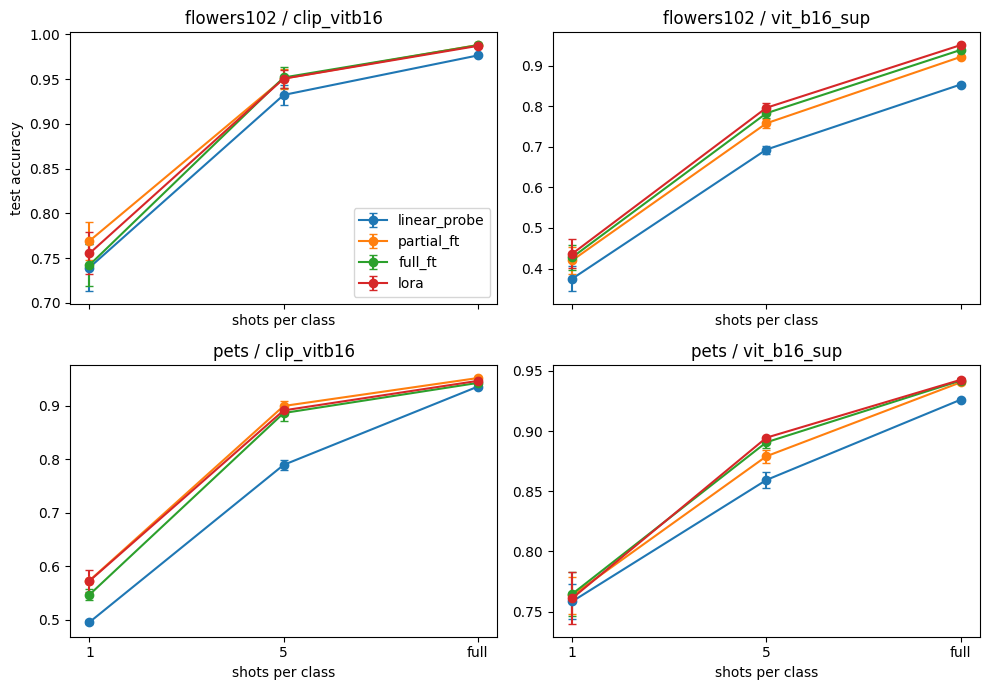

mean     std
dataset    backbone    method       shots                
flowers102 clip_vitb16 full_ft      1      0.7422  0.0240
                                    5      0.9519  0.0118
                                    full   0.9880  0.0006
                       linear_probe 1      0.7395  0.0266
                                    5      0.9323  0.0107
                                    full   0.9765  0.0008
                       lora         1      0.7552  0.0234
                                    5      0.9506  0.0100
                                    full   0.9872  0.0008
                       partial_ft   1      0.7692  0.0208
                                    5      0.9507  0.0112
                                    full   0.9882  0.0003
           vit_b16_sup full_ft      1      0.4277  0.0312
                                    5      0.7828  0.0123
                                    full   0.9386  0.0006
                       linear_probe 1      0.3749  0.0310
                                    5      0.6932  0.0100
                                    full   0.8535  0.0027
                       lora         1      0.4364  0.0356
                                    5      0.7962  0.0126
                                    full   0.9506  0.0011
                       partial_ft   1      0.4202  0.0337
                                    5      0.7580  0.0114
                                    full   0.9215  0.0014
pets       clip_vitb16 full_ft      1      0.5471  0.0107
                                    5      0.8867  0.0141
                                    full   0.9430  0.0015
                       linear_probe 1      0.4957  0.0041
                                    5      0.7898  0.0093
                                    full   0.9361  0.0013
                       lora         1      0.5728  0.0203
                                    5      0.8916  0.0077
                                    full   0.9469  0.0022
                       partial_ft   1      0.5735  0.0018
                                    5      0.8999  0.0089
                                    full   0.9521  0.0006
           vit_b16_sup full_ft      1      0.7646  0.0185
                                    5      0.8907  0.0046
                                    full   0.9419  0.0017
                       linear_probe 1      0.7584  0.0144
                                    5      0.8594  0.0070
                                    full   0.9260  0.0006
                       lora         1      0.7611  0.0217
                                    5      0.8945  0.0007
                                    full   0.9426  0.0018
                       partial_ft   1      0.7634  0.0153
                                    5      0.8791  0.0055
                                    full   0.9405  0.0015

In [8]:
# Results cell: accuracy versus shots for every dataset/backbone/method (mean +- std over the 3 seeds) and the summary table.
df = MAIN.rows().assign(shots=lambda d: d.shots.astype(str))
shot_labels = [str(k) for k in SHOTS]
summary = df.groupby(['dataset', 'backbone', 'method', 'shots']).test_acc.agg(['mean', 'std']).round(4)

# one panel per (dataset, backbone); x axis = shot setting (categorical because 'full' differs per dataset), one line per method
fig, axes = plt.subplots(len(DATASETS), len(BACKBONES), figsize=(10, 7), sharex=True, squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, bb in enumerate(BACKBONES):
        ax = axes[i, j]
        for m in METHODS:
            g = df[(df.dataset == ds) & (df.backbone == bb) & (df.method == m)].groupby('shots').test_acc.agg(['mean', 'std']).reindex(shot_labels)
            ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, label=m)
        ax.set(xticks=range(len(shot_labels)), xticklabels=shot_labels, title=f'{ds} / {bb}')
        ax.set_xlabel('shots per class')
axes[0, 0].set_ylabel('test accuracy')
axes[0, 0].legend()
plt.tight_layout()
plt.show()
summary


**Findings.** Test accuracy after the last step, mean over 3 seeds (the tables above give the std).

- **Supervised ViT-B/16:** LoRA has the highest mean in 5 of the 6 cells (Flowers102 with 1, 5 and all images per class, Pets with 5 and all). On Pets with 1 shot the four methods are within 0.007 of each other (0.758-0.765).
- **CLIP:** there is no single winner. Partial fine-tuning has the highest mean on Flowers102 with 1 shot (0.769) and on Pets with 5 shots and all the data (0.900, 0.952); on Pets with 1 shot partial FT and LoRA tie (0.574, 0.573); full fine-tuning has the highest mean on Flowers102 with 5 shots (0.952, against 0.951 for LoRA and partial FT), and with all the Flowers102 data full and partial FT tie at 0.988 (LoRA 0.987).
- **1 shot, CLIP:** full fine-tuning is below LoRA and partial FT (Flowers102 0.742 against 0.755-0.769, Pets 0.547 against 0.573-0.574), and the gap closes with more shots. These runs do not identify the cause: a learning rate fixed for all regimes may suit some methods better than others.
- **The linear probe has the lowest mean in every cell.** It is close to full FT for CLIP on Flowers102 at 1 shot (0.739 against 0.742) and far from the best method for the supervised backbone on Flowers102 (0.06-0.10 below LoRA) and for CLIP on Pets at 5 shots (0.790 against 0.900).
- Differences below about 0.01 are within the seed-to-seed standard deviation and are read as ties; the paired differences below make the comparisons precise. The learning rates are fixed and untuned, so these results are exploratory (Experiments 3 and 4 tune them).


#### Paired differences

The same seed gives the same k-shot subset to every method and backbone, so subtracting accuracies seed by seed removes the variance due to the subset. The first table gives full FT minus the linear probe and minus LoRA (> 0: full FT better); the second gives CLIP minus supervised (> 0: CLIP better, H3). Differences smaller than about 0.01, or smaller than the std, should be read as ties.


In [9]:
# Paired differences (same seed => same k-shot subset). H1/H2: full_ft vs the cheaper methods; H3: CLIP vs supervised.
# Pairing removes the variance due to the choice of the subset, so small differences are easier to see than with the plain means.
# String order '1' < '5' < 'full' matches the shot order.
acc = df.pivot_table(index=['dataset', 'backbone', 'shots', 'seed'], columns='method', values='test_acc')
paired = pd.DataFrame({'full_ft - linear_probe': acc.full_ft - acc.linear_probe, 'full_ft - lora': acc.full_ft - acc.lora})
display(paired.groupby(['dataset', 'backbone', 'shots']).agg(['mean', 'std']).round(3))

# H3: same dataset, method, shots and seed, CLIP minus supervised (> 0 means CLIP is better)
by_bb = df.pivot_table(index=['dataset', 'method', 'shots', 'seed'], columns='backbone', values='test_acc')
clip_gain = (by_bb.clip_vitb16 - by_bb.vit_b16_sup).rename('clip - sup')
clip_gain.groupby(['dataset', 'method', 'shots']).agg(['mean', 'std']).round(3)


full_ft - linear_probe        full_ft - lora  \
                                               mean    std           mean   
dataset    backbone    shots                                                
flowers102 clip_vitb16 1                      0.003  0.007         -0.013   
                       5                      0.020  0.001          0.001   
                       full                   0.011  0.001          0.001   
           vit_b16_sup 1                      0.053  0.008         -0.009   
                       5                      0.090  0.009         -0.013   
                       full                   0.085  0.003         -0.012   
pets       clip_vitb16 1                      0.051  0.015         -0.026   
                       5                      0.097  0.014         -0.005   
                       full                   0.007  0.002         -0.004   
           vit_b16_sup 1                      0.006  0.004          0.004   
                       5                      0.031  0.003         -0.004   
                       full                   0.016  0.002         -0.001   

                                     
                                std  
dataset    backbone    shots         
flowers102 clip_vitb16 1      0.010  
                       5      0.004  
                       full   0.001  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.001  
pets       clip_vitb16 1      0.012  
                       5      0.007  
                       full   0.003  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.003

mean    std
dataset    method       shots              
flowers102 full_ft      1      0.315  0.012
                        5      0.169  0.006
                        full   0.049  0.000
           linear_probe 1      0.365  0.010
                        5      0.239  0.004
                        full   0.123  0.003
           lora         1      0.319  0.013
                        5      0.154  0.004
                        full   0.037  0.002
           partial_ft   1      0.349  0.013
                        5      0.193  0.000
                        full   0.067  0.002
pets       full_ft      1     -0.217  0.029
                        5     -0.004  0.017
                        full   0.001  0.002
           linear_probe 1     -0.263  0.011
                        5     -0.070  0.016
                        full   0.010  0.002
           lora         1     -0.188  0.040
                        5     -0.003  0.007
                        full   0.004  0.004
           partial_ft   1     -0.190  0.015
                        5      0.021  0.013
                        full   0.012  0.002

**What this experiment can and cannot show.** The learning rates are fixed and untuned, and the training sets have at most 20-100 images/class, far below the hundreds of images/class at which H2 expects a crossover. The main study is therefore exploratory: the verdicts are drawn from Experiments 3 and 4, which tune the learning rate on a validation set, and its numbers are used only as exploratory evidence in section 7.

### Experiment 2: replication of CLIP-LoRA (pipeline check)

The main study differs from CLIP-LoRA (Zanella & Ben Ayed, 2024) on purpose (image tower only, zero-initialised linear head, small budget). To check that the pipeline is not the cause of the gap at 1-4 shots, this section re-implements their protocol, from the paper and, where the paper is silent, from the official code (github.com/MaxZanella/CLIP-LoRA), and compares with their Table 3 (CLIP ViT-B/16, Flowers102 and Pets):

- CLIP ViT-B/16 (OpenAI weights, `transformers`), both image and text towers adapted. The class weights are the text embeddings of "a photo of a [class]." computed at every step by the adapted text encoder, so training starts from the zero-shot classifier of that prompt; logits are cosine similarities scaled by CLIP's temperature (100).
- LoRA on the query, key and value projections of every attention block of both towers, rank 2, dropout 0.25 on the LoRA input, A Kaiming-initialised and B initialised at zero (paper); scaling alpha/sqrt(r) with alpha = 1, i.e. 1/sqrt(2) (official code, `loralib/layers.py`; the paper does not give the value).
- lr 2e-4, cosine schedule, batch 32, 500 x shots/class iterations (paper); AdamW with weight decay 0.01 and a final learning rate of 1e-6 (official code); no validation set, last iterate evaluated.
- Training augmentation `RandomResizedCrop(224, scale=(0.08, 1))` (bicubic) + horizontal flip; test: resize 224 (bicubic) + center crop (official code).
- Seeds 0, 1, 2 and the k-shot sampler of the main study (the 1-shot subsets are those of the main study; the paper's subsets are necessarily different), shots 1 and 4. 16 shots (8000 steps per run) were not run.
- Known differences: official Flowers102 test split (6,149 images) instead of the CoOp split (2,463; for Pets both use the official test split, 3,669 images); class names from the OpenAI/CLIP-benchmark list instead of CoOp's; bf16 autocast instead of fp16 with gradient scaling. Zero-shot accuracy is evaluated as a sanity check of the pipeline (paper: Flowers 71.4, Pets 89.1).
- `results/replication_scale_alpha_over_r.csv` holds the same runs with the scaling alpha/r = 1/2 and a final learning rate of 0; they are shown next to the runs with the official values as a sensitivity check of these two details.


In [10]:
# Replication of the CLIP-LoRA protocol (Zanella & Ben Ayed, 2024): text-initialised classifier, LoRA on both CLIP towers.
from transformers import CLIPModel, CLIPTokenizer

REPLICATION = RunLog('replication')
HF_CLIP = 'openai/clip-vit-base-patch16'
_names = json.load(open(DATA_ROOT / 'en_classnames.json'))  # CLIP-benchmark list, same order as the torchvision labels
CLASSNAMES = {'flowers102': _names['flowers'], 'pets': _names['pets']}
# hyperparameters of the paper (rank 2, dropout 0.25, lr 2e-4, cosine schedule, batch 32, 500 iterations per shot) and of the official code
# where the paper is silent (AdamW, weight decay 0.01, LoRA scaling alpha / sqrt(rank) with alpha = 1, final lr 1e-6)
REP = dict(rank=2, alpha=1, dropout=0.25, lr=2e-4, wd=0.01, bs=32, iters_per_shot=500, eta_min=1e-6)
REP_SHOTS = [1, 4]
BICUBIC = T.InterpolationMode.BICUBIC
# CLIP-style augmentation (strong random crop) and bicubic evaluation resize, as in the paper's protocol
REP_TRAIN_TF = T.Compose([T.RandomResizedCrop(224, scale=(0.08, 1.0), interpolation=BICUBIC), T.RandomHorizontalFlip(),
                          T.ToTensor(), T.Normalize(*NORM['clip_vitb16'])])
REP_TEST_TF = T.Compose([T.Resize(224, interpolation=BICUBIC), T.CenterCrop(224), T.PILToTensor()])
_REP_TEST = {}

class LoRALinearDropout(LoRALinear):
    """LoRALinear with dropout applied to the input of the low-rank branch only (the frozen path is untouched) and the scaling of the
    official CLIP-LoRA code, alpha / sqrt(rank) (loralib/layers.py), instead of alpha / rank."""
    def __init__(self, base, rank, alpha, dropout):
        super().__init__(base, rank, alpha)
        self.scale = alpha / math.sqrt(rank)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + (self.drop(x) @ self.A.T @ self.B.T) * self.scale

class ClipClassifier(nn.Module):
    """CLIP with a text-embedding classifier (prompt `template`); LoRA on q/k/v of both towers when lora=True."""
    def __init__(self, classnames, lora, template='a photo of a {}.'):
        super().__init__()
        self.clip = CLIPModel.from_pretrained(HF_CLIP)
        tok = CLIPTokenizer.from_pretrained(HF_CLIP)
        # one prompt per class; the classifier weights are the (adapted) text embeddings of these prompts
        self.tokens = tok([template.format(c) for c in classnames], padding=True, return_tensors='pt')
        for p in self.clip.parameters():
            p.requires_grad = False
        if lora:
            for tower in (self.clip.vision_model, self.clip.text_model):
                for layer in tower.encoder.layers:
                    for name in ('q_proj', 'k_proj', 'v_proj'):
                        setattr(layer.self_attn, name, LoRALinearDropout(getattr(layer.self_attn, name), REP['rank'], REP['alpha'], REP['dropout']))

    def text_features(self):
        t = {k: v.to(self.clip.device) for k, v in self.tokens.items()}
        return F.normalize(self.clip.get_text_features(**t), dim=-1)

    def forward(self, x, text=None):
        # logits = learned temperature x cosine similarity between image and class-text embeddings
        text = self.text_features() if text is None else text
        return self.clip.logit_scale.exp() * F.normalize(self.clip.get_image_features(pixel_values=x), dim=-1) @ text.T

def rep_test_set(name):
    # Decode the test images once (uint8) with the replication's own evaluation transform.
    if name not in _REP_TEST:
        _REP_TEST[name] = u8_tensors(load_dataset(name, 'clip_vitb16', test_tf=REP_TEST_TF)[2])
    return _REP_TEST[name]

@torch.no_grad()
def rep_evaluate(model, name):
    model.eval()
    x_u8, y = rep_test_set(name)
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM['clip_vitb16'])
    with torch.autocast(DEVICE, dtype=torch.bfloat16):
        text = model.text_features()  # computed once for the whole test set
        correct = sum((model((x_u8[i:i + 128].to(DEVICE).float() / 255 - mean) / std, text).argmax(1).cpu() == y[i:i + 128]).sum().item()
                      for i in range(0, len(y), 128))
    return correct / len(y)

def run_replication(dataset, shots, seed):
    """shots = 0: zero-shot evaluation of the same pipeline."""
    set_seed(seed)
    model = ClipClassifier(CLASSNAMES[dataset], lora=shots > 0).to(DEVICE)
    if shots > 0:
        train_ds, labels, _ = load_dataset(dataset, 'clip_vitb16', train_tf=REP_TRAIN_TF)
        idx = few_shot_indices(labels, shots, seed)  # same k-shot subsets as the main study
        loader = DataLoader(Subset(train_ds, idx), batch_size=min(REP['bs'], len(idx)), shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=REP['lr'], weight_decay=REP['wd'])
        steps = REP['iters_per_shot'] * shots
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=REP['eta_min'])
        model.train()
        for x, y in batches(loader, steps):
            with torch.autocast(DEVICE, dtype=torch.bfloat16):
                loss = F.cross_entropy(model(x).float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
    return rep_evaluate(model, dataset)

# Resumable loop: zero-shot once per dataset (deterministic), then 1 and 4 shots for 3 seeds.
jobs = [(ds_, 0, 0) for ds_ in CLASSNAMES] + [(ds_, k_, s_) for ds_ in CLASSNAMES for k_ in REP_SHOTS for s_ in SEEDS]
for ds_, k_, s_ in jobs:
    keys = dict(dataset=ds_, shots=k_, seed=s_)
    if not REPLICATION.done(**keys):
        REPLICATION.record(keys, lambda: dict(test_acc=run_replication(ds_, k_, s_)))


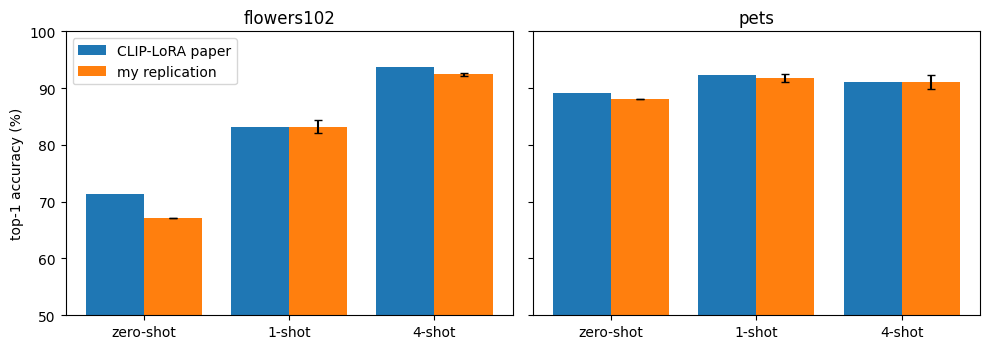

mean  std  paper  mine - paper  alpha / r scaling  \
dataset    shots                                                      
flowers102 0      67.2  NaN   71.4          -4.2               67.2   
           1      83.2  1.1   83.2           0.0               82.7   
           4      92.4  0.3   93.7          -1.3               92.3   
pets       0      88.1  NaN   89.1          -1.0               88.1   
           1      91.7  0.7   92.3          -0.6               92.0   
           4      91.1  1.2   91.0           0.1               91.5   

                  main study LoRA (1 / 5 shots)  
dataset    shots                                 
flowers102 0                                NaN  
           1                               75.5  
           4                               95.1  
pets       0                                NaN  
           1                               57.3  
           4                               89.2

In [11]:
# Replication analysis: my numbers versus Table 3 of the CLIP-LoRA paper, plus the main-study LoRA for reference.
# CLIP-LoRA (Zanella & Ben Ayed 2024), Table 3, ViT-B/16, top-1 %, 3 seeds; key = (dataset, shots), 0 = zero-shot
PAPER = {('flowers102', 0): 71.4, ('flowers102', 1): 83.2, ('flowers102', 4): 93.7,
         ('pets', 0): 89.1, ('pets', 1): 92.3, ('pets', 4): 91.0}
rep = REPLICATION.rows()
tab_rep = rep.groupby(['dataset', 'shots']).test_acc.agg(['mean', 'std']).mul(100).round(1)
tab_rep['paper'] = [PAPER[i] for i in tab_rep.index]
tab_rep['mine - paper'] = (tab_rep['mean'] - tab_rep['paper']).round(1)
# the same runs with LoRA scaling alpha / rank and final lr 0, instead of alpha / sqrt(rank) and 1e-6 of the official code
tab_rep['alpha / r scaling'] = RunLog('replication_scale_alpha_over_r').rows().groupby(['dataset', 'shots']).test_acc.mean().mul(100).round(1)
# main study (image tower, zero-initialised head, 1 shot / 5 shots) for reference
main_lora = df[(df.backbone == 'clip_vitb16') & (df.method == 'lora')].groupby(['dataset', 'shots']).test_acc.mean().mul(100).round(1)
tab_rep['main study LoRA (1 / 5 shots)'] = [main_lora.get((d, {1: '1', 4: '5'}.get(k)), np.nan) for d, k in tab_rep.index]

# bar chart: paper vs my replication, one panel per dataset (the zero-shot bar has no std: single deterministic run)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, d in zip(axes, CLASSNAMES):
    g = tab_rep.loc[d]
    x = np.arange(len(g))
    ax.bar(x - 0.2, g['paper'], 0.4, label='CLIP-LoRA paper')
    ax.bar(x + 0.2, g['mean'], 0.4, yerr=g['std'].fillna(0), capsize=3, label='my replication')
    ax.set(xticks=x, xticklabels=['zero-shot' if k == 0 else f'{k}-shot' for k in g.index], title=d, ylim=(50, 100))
axes[0].set_ylabel('top-1 accuracy (%)')
axes[0].legend()
plt.tight_layout()
plt.show()
tab_rep


#### Zero-shot with CoOp's prompts

The zero-shot row of CLIP-LoRA's Table 3 (Flowers 71.4, Pets 89.1) is higher than my plain-prompt zero-shot, and the paper does not say which prompts produced it (its code uses "a photo of a {}."; CoOp's hand-crafted templates are present but commented out). This check evaluates zero-shot CLIP ViT-B/16 with CoOp's templates (CoOp Table 6): "a photo of a [class], a type of flower." and "a photo of a [class], a type of pet.". No training; the trained replication runs keep the plain prompt of the paper. Class names are still the OpenAI/CLIP-benchmark list and the Flowers102 test split is the official one, so a residual difference is possible.

In [12]:
# Zero-shot with CoOp's hand-crafted prompts (no training), against the plain prompt of the replication and the paper's zero-shot row.
COOP_TEMPLATE = {'flowers102': 'a photo of a {}, a type of flower.', 'pets': 'a photo of a {}, a type of pet.'}
ZERO_SHOT_COOP = RunLog('replication_zeroshot_coop_prompts')
for d, t in COOP_TEMPLATE.items():
    if not ZERO_SHOT_COOP.done(dataset=d):
        ZERO_SHOT_COOP.record(dict(dataset=d, prompt=t), lambda: dict(test_acc=rep_evaluate(ClipClassifier(CLASSNAMES[d], lora=False, template=t).to(DEVICE), d)))
zs = ZERO_SHOT_COOP.rows().set_index('dataset')
zs_tab = pd.DataFrame({'plain prompt (mine)': tab_rep.xs(0, level='shots')['mean'], 'CoOp prompt (mine)': zs.test_acc.mul(100).round(1),
                       'paper zero-shot row': [PAPER[(d, 0)] for d in zs.index]})
zs_tab['CoOp prompt - paper'] = (zs_tab['CoOp prompt (mine)'] - zs_tab['paper zero-shot row']).round(1)
zs_tab

,plain prompt (mine),CoOp prompt (mine),paper zero-shot row,CoOp prompt - paper
dataset,,,,
flowers102,67.2,71.2,71.4,-0.2
pets,88.1,89.1,89.1,0.0


#### Replication results

Top-1 accuracy (%), mean +- std over 3 seeds (zero-shot: one deterministic run); CLIP-LoRA values from Table 3 of the paper. "alpha/r scaling" are the same runs with the scaling alpha/r and a final learning rate of 0 (see the protocol above).

| dataset | shots | mine | alpha/r scaling | CLIP-LoRA paper | mine - paper |
|---|---|---|---|---|---|
| Flowers102 | 0 (zero-shot) | 67.2 (CoOp prompt: 71.2) | 67.2 | 71.4 | -4.2 (CoOp prompt: -0.2) |
| Flowers102 | 1 | 83.2 +- 1.1 | 82.7 | 83.2 | 0.0 |
| Flowers102 | 4 | 92.4 +- 0.3 | 92.3 | 93.7 | -1.3 |
| Pets | 0 (zero-shot) | 88.1 (CoOp prompt: 89.1) | 88.1 | 89.1 | -1.0 (CoOp prompt: 0.0) |
| Pets | 1 | 91.7 +- 0.7 | 92.0 | 92.3 | -0.6 |
| Pets | 4 | 91.1 +- 1.2 | 91.5 | 91.0 | +0.1 |

- **The protocol is reproduced.** Three of the four trained cells are within 0.6 points of the paper, inside my seed-to-seed standard deviation; Flowers 4-shot is 1.3 points lower. Possible causes, not isolated: the different test split (6,149 images vs 2,463), the class-name list, bf16 instead of fp16. The official LoRA scaling changes the results by at most 0.5 points with respect to alpha/r, within seed noise.
- **Zero-shot: the gap is the prompt, not the pipeline.** With the plain prompt of the paper and of its code I get 67.2 (Flowers) and 88.1 (Pets); with CoOp's hand-crafted prompts ("..., a type of flower." / "..., a type of pet.") I get 71.2 and 89.1, against 71.4 and 89.1 in the paper. So the paper's zero-shot row was obtained with CoOp's prompts, while its training starts from the plain prompt, as in its code.
- **What this shows for the main study:** with the same CLIP backbone and LoRA, going from the main-study setting (image tower only, zero-initialised head, about 100 steps) to the CLIP-LoRA setting (text-initialised classifier, both towers, 500 x shots steps) moves Pets 1-shot from 57.3% to 91.7% and Flowers 1-shot from 75.5% to 83.2%. The low main-study values at 1 shot are therefore a property of the protocol (no text prior), not of the pipeline. 16-shot runs (8000 steps each) were not run.


### Experiment 3: EuroSAT scaling study (tuned learning rates)

**Why.** In the main study the largest training set is 20 images/class on Flowers102 (2,040 images) and about 100/class on Pets (3,680 images). H2 predicts a crossover where full fine-tuning overtakes the cheaper methods with hundreds or thousands of images per class, a regime the main study never reaches. In addition the learning rates were fixed a priori, which can favour one method (H1). This experiment removes both limitations on a dataset with many images per class; EuroSAT is also far from both pre-training distributions, so it is a domain-shift test as well. Running the supervised backbone too makes the H3 comparison like-for-like. EuroSAT was chosen *after* the main-study results (post hoc).

**Dataset.** EuroSAT with the split of section 3: 4,000 test and 1,000 validation images, and a pool of at least 1,500 images/class (Pasture has only 2,000 images in total).

**Protocol.**

- Shots per class: 1, 5, 20, 100, 500, 1500; two backbones, the CLIP ViT-B/16 image tower and the supervised ViT-B/16 (ImageNet-1k), each with a zero-initialised linear head, and the four methods of the main study (same `PARTIAL_K` = 4 and LoRA rank 8).
- **H3 is tested here under matched conditions:** both backbones see the same k-shot subsets (same seed), the same validation and test images, the same budget and the same learning-rate grids with the same tuning rule, and neither uses a text tower (unlike the replication, Experiment 2, where CLIP's text encoder is the classifier).
- Learning rate chosen with the tuned protocol of section 4 from a grid of 4 values per method: linear probe head lr {3e-4, 1e-3, 3e-3, 1e-2}; `partial_ft` and `full_ft` backbone lr {3e-6, 1e-5, 3e-5, 1e-4}; LoRA lr {1.5e-4, 5e-4, 1.5e-3, 5e-3}; head lr 1e-3 for the other methods. The main-study values are in the grids.
- Budget: 10 epochs over the subset, at least 100 and at most 1,500 optimizer steps (so 500 and 1,500 images/class get 1,500 steps, about 9.6 and 3.2 epochs).
- The validation set (1,000 images) is larger than the training set at low shot counts, which is not a realistic few-shot setting: tuned results at 1-20 shots are optimistic, and not necessarily by the same amount for every method (the tuning gain depends on the method and the backbone, see the findings).


In [13]:
# Experiment 3: EuroSAT, both backbones, 1-1,500 images/class, learning rate tuned per (backbone, method, shots); one log per backbone.
SCALE_SHOTS = [1, 5, 20, 100, 500, 1500]
SCALE_GRID = {  # method: (hyperparameter that is tuned, values); identical for both backbones
    'linear_probe': ('head_lr', [3e-4, 1e-3, 3e-3, 1e-2]),
    'partial_ft': ('body_lr', [3e-6, 1e-5, 3e-5, 1e-4]),
    'full_ft': ('body_lr', [3e-6, 1e-5, 3e-5, 1e-4]),
    'lora': ('body_lr', [1.5e-4, 5e-4, 1.5e-3, 5e-3]),
}
SCALE = {'clip_vitb16': RunLog('scaling_eurosat'), 'vit_b16_sup': RunLog('scaling_eurosat_vit_b16_sup')}

def run_scaling(backbone, method, shots, lr, seed, **budget):
    split, train_ds = eurosat(backbone)
    return run_tuned_lr(split, train_ds, backbone, method, shots, lr, seed, SCALE_GRID, **budget)

for bb_ in BACKBONES:
    for shots_ in SCALE_SHOTS:
        for method_, (_, lrs_) in SCALE_GRID.items():
            tune_lr(SCALE[bb_], lambda lr, seed: run_scaling(bb_, method_, shots_, lr, seed), lrs_, method=method_, shots=shots_)

#### Reading the figures

One row per backbone. **Column 1:** test accuracy against training images per class (log axis). **Column 2:** paired difference full FT - other method; a crossover would be a curve going from below 0 to above 0. **Column 3:** learning rate selected on validation; values on the edge of the grid mean the optimum may lie outside it. The tables report accuracy (mean, std over seeds), the paired differences, the selected learning rates and the tuning gain (tuned minus main-study learning rate, seed 0). The last figure and table compare the two backbones (CLIP - supervised, H3).


===== clip_vitb16: test accuracy (mean, std over seeds), difference full FT - method, selected lr, tuning gain =====


mean                                    std                      \
method full_ft linear_probe   lora partial_ft full_ft linear_probe   lora   
shots                                                                       
1        0.634        0.529  0.665      0.583   0.085        0.057  0.085   
5        0.836        0.761  0.839      0.816   0.021        0.048  0.021   
20       0.924        0.850  0.914      0.906   0.001        0.005  0.005   
100      0.959        0.908  0.956      0.949   0.006        0.009  0.005   
500      0.977        0.931  0.975      0.972   0.002        0.001  0.003   
1500     0.983        0.942  0.980      0.978   0.001        0.001  0.004   

                   
method partial_ft  
shots              
1           0.080  
5           0.017  
20          0.006  
100         0.008  
500         0.001  
1500        0.001

full_ft - linear_probe        full_ft - partial_ft         \
                        mean    std                 mean    std   
shots                                                             
1                      0.106  0.032                0.052  0.008   
5                      0.075  0.029                0.020  0.023   
20                     0.074  0.005                0.017  0.007   
100                    0.050  0.007                0.010  0.003   
500                    0.046  0.003                0.005  0.002   
1500                   0.041  0.001                0.005  0.001   

      full_ft - lora         
                mean    std  
shots                        
1             -0.031  0.020  
5             -0.003  0.007  
20             0.010  0.006  
100            0.003  0.002  
500            0.002  0.004  
1500           0.002  0.003

method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.000003,0.010,0.00050,0.00003
5,0.000003,0.010,0.00015,0.00010
20,0.000003,0.003,0.00050,0.00003
100,0.000003,0.010,0.00150,0.00010
500,0.000010,0.003,0.00015,0.00003
1500,0.000003,0.010,0.00015,0.00010


test accuracy, tuned minus main-study default lr (seed 0 only):


...

mean                                    std                      \
method full_ft linear_probe   lora partial_ft full_ft linear_probe   lora   
shots                                                                       
1        0.602        0.497  0.602      0.573   0.040        0.028  0.025   
5        0.771        0.706  0.802      0.777   0.012        0.010  0.008   
20       0.910        0.796  0.913      0.897   0.003        0.010  0.010   
100      0.958        0.901  0.959      0.953   0.005        0.005  0.001   
500      0.978        0.940  0.975      0.976   0.000        0.003  0.003   
1500     0.981        0.946  0.980      0.982   0.002        0.003  0.000   

                   
method partial_ft  
shots              
1           0.044  
5           0.015  
20          0.013  
100         0.004  
500         0.002  
1500        0.000

full_ft - linear_probe        full_ft - partial_ft         \
                        mean    std                 mean    std   
shots                                                             
1                      0.105  0.018                0.029  0.008   
5                      0.066  0.021               -0.005  0.023   
20                     0.114  0.009                0.012  0.013   
100                    0.057  0.007                0.005  0.004   
500                    0.038  0.003                0.002  0.002   
1500                   0.034  0.001               -0.002  0.003   

      full_ft - lora         
                mean    std  
shots                        
1              0.000  0.046  
5             -0.031  0.010  
20            -0.003  0.007  
100           -0.001  0.004  
500            0.002  0.003  
1500           0.001  0.002

method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.00010,0.003,0.0050,0.0001
5,0.00003,0.003,0.0015,0.0001
20,0.00010,0.001,0.0050,0.0001
100,0.00003,0.003,0.0015,0.0001
500,0.00003,0.010,0.0015,0.0001
1500,0.00010,0.003,0.0005,0.0001


test accuracy, tuned minus main-study default lr (seed 0 only):


method,full_ft,linear_probe,lora,partial_ft
shots,,,,
1,0.062,0.002,0.043,0.047
5,0.029,-0.006,0.057,0.044
20,0.048,0.000,0.029,0.077
100,0.011,0.018,0.006,0.033
500,0.001,0.011,-0.001,0.011
1500,-0.002,0.009,0.000,0.014


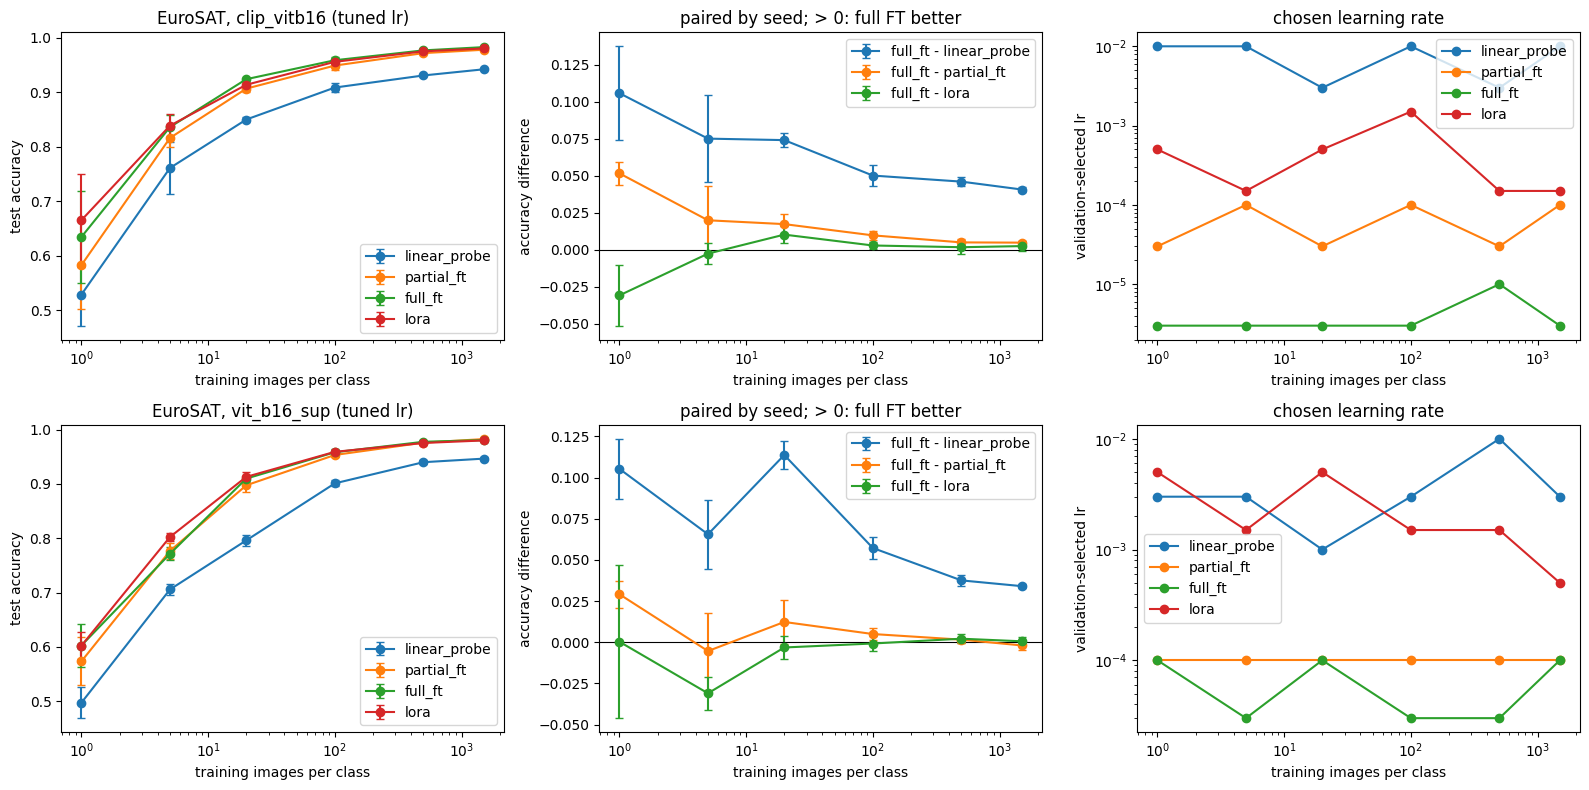

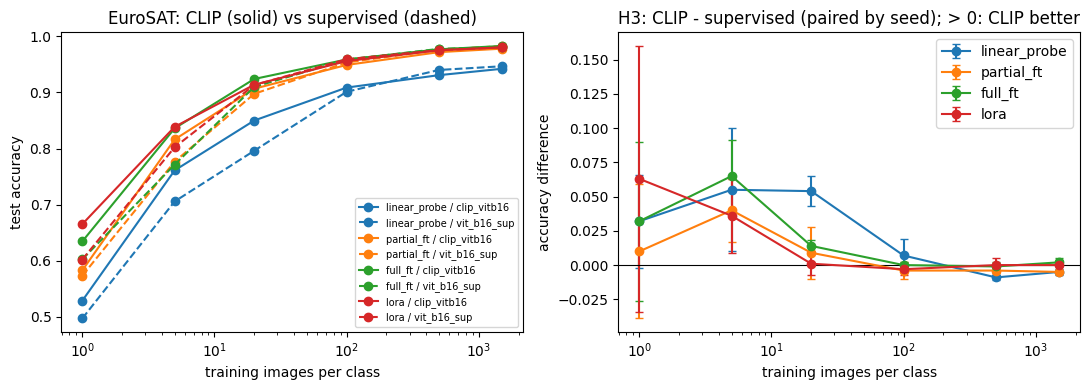

H3: CLIP - supervised, mean and std over seeds


linear_probe        partial_ft        full_ft          lora       
              mean    std       mean    std    mean    std   mean    std
shots                                                                   
1            0.032  0.034      0.010  0.049   0.032  0.058  0.063  0.097
5            0.055  0.045      0.040  0.023   0.065  0.026  0.036  0.027
20           0.054  0.011      0.009  0.019   0.014  0.004  0.001  0.008
100          0.007  0.012     -0.004  0.006   0.000  0.002 -0.003  0.004
500         -0.009  0.002     -0.004  0.002  -0.001  0.003 -0.000  0.005
1500        -0.005  0.002     -0.005  0.001   0.002  0.003  0.000  0.004

In [14]:
# Scaling analysis: accuracy tables and plots per backbone, then the matched CLIP-vs-supervised comparison (H3).
default_lr = {'linear_probe': HEAD_LR, **BODY_LR}  # main-study values, to measure the tuning gain
FIN, PIV = {}, {}  # FIN: test rows of the selected lr per backbone; PIV: accuracy pivoted by seed (for paired differences)
fig, axes = plt.subplots(len(BACKBONES), 3, figsize=(16, 4 * len(BACKBONES)))
for r, bb_ in enumerate(BACKBONES):
    sc = SCALE[bb_].rows()
    if sc.empty:
        continue
    # selected lr = best validation accuracy on seed 0 (same rule as the run cell); fin = its test accuracy on seeds 0-2
    seed0 = sc[sc.seed == 0]
    best = best_lr(sc, ['method', 'shots']).rename(columns={'lr': 'best_lr'})
    fin = selected_runs(sc, ['method', 'shots'])
    FIN[bb_] = fin

    acc_tab = fin.groupby(['shots', 'method']).test_acc.agg(['mean', 'std']).unstack('method').round(3)
    lr_tab = best.pivot(index='shots', columns='method', values='best_lr')
    piv = fin.pivot_table(index=['shots', 'seed'], columns='method', values='test_acc')
    PIV[bb_] = piv
    # paired by seed (same subset): full FT minus each other method
    diff_tab = pd.concat({f'full_ft - {m}': (piv.full_ft - piv[m]).groupby('shots').agg(['mean', 'std']) for m in METHODS if m != 'full_ft'}, axis=1).round(3)
    # how much tuning helps: seed-0 test accuracy at the selected lr minus at the main-study default lr
    s0 = seed0.assign(default=seed0.method.map(default_lr))
    acc_default = s0[np.isclose(s0.lr, s0.default)].set_index(['method', 'shots']).test_acc
    acc_tuned = fin[fin.seed == 0].set_index(['method', 'shots']).test_acc
    tune_gain = (acc_tuned - acc_default).unstack('method').round(3)

    # column 1: accuracy versus training images per class (log x axis)
    for m in METHODS:
        g = fin[fin.method == m].groupby('shots').test_acc.agg(['mean', 'std'])
        axes[r, 0].errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3, label=m)
    axes[r, 0].set(xscale='log', xlabel='training images per class', ylabel='test accuracy', title=f'EuroSAT, {bb_} (tuned lr)')
    axes[r, 0].legend()
    # column 2: paired difference full FT - method; a crossover would be a curve going from below 0 to above 0
    for m in METHODS:
        if m != 'full_ft':
            d = (piv.full_ft - piv[m]).groupby('shots').agg(['mean', 'std'])
            axes[r, 1].errorbar(d.index, d['mean'], d['std'], marker='o', capsize=3, label=f'full_ft - {m}')
    axes[r, 1].axhline(0, color='k', lw=0.8)
    axes[r, 1].set(xscale='log', xlabel='training images per class', ylabel='accuracy difference', title='paired by seed; > 0: full FT better')
    axes[r, 1].legend()
    # column 3: selected learning rate (points on the grid edge suggest the optimum may lie outside the grid)
    for m in METHODS:
        axes[r, 2].plot(lr_tab.index, lr_tab[m], marker='o', label=m)
    axes[r, 2].set(xscale='log', yscale='log', xlabel='training images per class', ylabel='validation-selected lr', title='chosen learning rate')
    axes[r, 2].legend()
    print(f'===== {bb_}: test accuracy (mean, std over seeds), difference full FT - method, selected lr, tuning gain =====')
    display(acc_tab)
    display(diff_tab)
    display(lr_tab)
    print('test accuracy, tuned minus main-study default lr (seed 0 only):')
    display(tune_gain)
plt.tight_layout()
plt.show()

# H3: same seed => same k-shot subset and same test set, so CLIP - supervised is paired by seed
if len(PIV) == 2:
    h3 = pd.concat({m: (PIV['clip_vitb16'][m] - PIV['vit_b16_sup'][m]).groupby('shots').agg(['mean', 'std']) for m in METHODS}, axis=1).round(3)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for m in METHODS:
        for bb_, ls in zip(BACKBONES, ['-', '--']):
            g = FIN[bb_][FIN[bb_].method == m].groupby('shots').test_acc.mean()
            axes[0].plot(g.index, g.values, ls, marker='o', color=f'C{METHODS.index(m)}', label=f'{m} / {bb_}')
        axes[1].errorbar(h3[m].index, h3[m]['mean'], h3[m]['std'], marker='o', capsize=3, label=m)
    axes[0].set(xscale='log', xlabel='training images per class', ylabel='test accuracy', title='EuroSAT: CLIP (solid) vs supervised (dashed)')
    axes[0].legend(fontsize=7)
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set(xscale='log', xlabel='training images per class', ylabel='accuracy difference', title='H3: CLIP - supervised (paired by seed); > 0: CLIP better')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    print('H3: CLIP - supervised, mean and std over seeds')
    display(h3)


#### Findings

EuroSAT, test accuracy at the validation-selected learning rate, mean +- std over 3 seeds; differences are paired by seed (same k-shot subset and test set for both backbones).

**CLIP ViT-B/16**

| images/class | full FT | LoRA | partial FT | linear probe |
|---|---|---|---|---|
| 1 | 0.634 +- 0.085 | 0.665 +- 0.085 | 0.583 +- 0.080 | 0.529 +- 0.057 |
| 5 | 0.836 +- 0.021 | 0.839 +- 0.021 | 0.816 +- 0.017 | 0.761 +- 0.048 |
| 20 | 0.924 +- 0.001 | 0.914 +- 0.005 | 0.906 +- 0.006 | 0.850 +- 0.005 |
| 100 | 0.959 +- 0.006 | 0.956 +- 0.005 | 0.949 +- 0.008 | 0.908 +- 0.009 |
| 500 | 0.977 +- 0.002 | 0.975 +- 0.003 | 0.972 +- 0.001 | 0.931 +- 0.001 |
| 1500 | 0.983 +- 0.001 | 0.980 +- 0.004 | 0.978 +- 0.001 | 0.942 +- 0.001 |

**Supervised ViT-B/16 (ImageNet-1k)**

| images/class | full FT | LoRA | partial FT | linear probe |
|---|---|---|---|---|
| 1 | 0.602 +- 0.040 | 0.602 +- 0.025 | 0.573 +- 0.044 | 0.497 +- 0.028 |
| 5 | 0.771 +- 0.012 | 0.802 +- 0.008 | 0.777 +- 0.015 | 0.706 +- 0.010 |
| 20 | 0.910 +- 0.003 | 0.913 +- 0.010 | 0.897 +- 0.013 | 0.796 +- 0.010 |
| 100 | 0.958 +- 0.005 | 0.959 +- 0.001 | 0.953 +- 0.004 | 0.901 +- 0.005 |
| 500 | 0.978 +- 0.000 | 0.975 +- 0.003 | 0.976 +- 0.002 | 0.940 +- 0.003 |
| 1500 | 0.981 +- 0.002 | 0.980 +- 0.000 | 0.982 +- 0.000 | 0.946 +- 0.003 |

**Full FT - LoRA (paired by seed, mean +- std)**

| images/class | CLIP | supervised |
|---|---|---|
| 1 | -0.031 +- 0.020 | 0.000 +- 0.046 |
| 5 | -0.003 +- 0.007 | -0.031 +- 0.010 |
| 20 | +0.010 +- 0.006 | -0.003 +- 0.007 |
| 100 | +0.003 +- 0.002 | -0.001 +- 0.004 |
| 500 | +0.002 +- 0.004 | +0.002 +- 0.003 |
| 1500 | +0.002 +- 0.003 | +0.001 +- 0.002 |

**CLIP - supervised (H3, paired by seed, mean)**

| images/class | linear probe | partial FT | full FT | LoRA |
|---|---|---|---|---|
| 1 | +0.032 | +0.010 | +0.032 | +0.063 |
| 5 | +0.055 | +0.040 | +0.065 | +0.036 |
| 20 | +0.054 | +0.009 | +0.014 | +0.001 |
| 100 | +0.007 | -0.004 | 0.000 | -0.003 |
| 500 | -0.009 | -0.004 | -0.001 | 0.000 |
| 1500 | -0.005 | -0.005 | +0.002 | 0.000 |

- **Low shots: LoRA is at least as good as full FT.** LoRA is clearly better for CLIP at 1 image/class (full FT - LoRA = -0.031 +- 0.020; per seed -0.007, -0.039, -0.046) and for the supervised backbone at 5 (-0.031 +- 0.010); the other two cells are ties (CLIP at 5: -0.003 +- 0.007; supervised at 1: 0.000 +- 0.046, per seed +0.011, -0.051, +0.040, i.e. noise).
- **No crossover between full FT and LoRA.** From 20 images/class on, full FT - LoRA is between -0.003 and +0.010 for both backbones. The largest value, CLIP at 20 images/class (+0.010 +- 0.006, positive on all seeds), sits at the 0.01 threshold; from 100 images/class on every value is within +-0.003. For CLIP the difference thus goes from clearly negative at 1 image/class to a marginal advantage of full FT at 20-100 (+0.010, +0.003): full FT catches up with LoRA but does not pull ahead beyond the tie threshold.
- **Partial FT stays below full FT for CLIP.** Full FT - partial FT is positive on all seeds at every size: +0.052, +0.020 +- 0.023, +0.017, +0.010, +0.005, +0.005 (1 to 1,500 images/class). For the supervised backbone it is +0.029 at 1 image/class (an artefact of the grid edge, see Check 2) and between -0.005 and +0.012 afterwards.
- **The linear probe is the weakest method at every size**, for both backbones and on all seeds. The gap to full FT is smaller with more data (CLIP +0.106 at 1 image/class and +0.041 at 1,500, supervised +0.105 and +0.034; not monotonically, e.g. the supervised gap is largest at 20 images/class, +0.114) but never closes.
- **H3: CLIP is better at 5-20 images/class, the two backbones are equal from 100.** At 5 images/class CLIP is ahead for all four methods with the same sign on all seeds (+0.036 to +0.065); at 20 images/class for full FT (+0.014 +- 0.004) and the linear probe (+0.054 +- 0.011), while LoRA and partial FT tie. At 1 image/class the means are positive (+0.010 to +0.063) but one seed in three is negative for every method (std 0.034-0.097), so the sign is not established. From 100 images/class all differences are below 0.01 (the supervised backbone is ahead by 0.004-0.009 for the linear probe and partial FT at 500-1,500, below the threshold).
- **Tuning matters more for the supervised backbone.** At seed 0, the validation-selected learning rate changes test accuracy relative to the fixed defaults of the main study by up to +0.062 (full FT), +0.057 (LoRA) and +0.077 (partial FT) for the supervised backbone at 1-20 images/class, but only by at most +0.033 (full FT), +0.020 (partial FT) and 0.000 (LoRA) for CLIP; the linear probe gains at most 0.030 for CLIP and 0.002 for the supervised backbone at 1-20 images/class (0.032 and 0.018 at 100 images/class and above). Comparisons across backbones at fixed learning rates therefore favour CLIP for the fine-tuning methods.
- **Grid edges.** CLIP: full FT at the lower edge (3e-6) for 5 of 6 shot counts, linear probe at the upper edge (1e-2) for 4, partial FT at the upper edge (1e-4) for 3, LoRA at the lower edge (1.5e-4) for 3. Supervised: linear probe at the upper edge for 1, partial FT at the upper edge for 6 of 6, full FT at the upper edge (1e-4) for 3, LoRA at the upper edge (5e-3) for 2: 27 of 48 cells in total. Check 2 (section 6.3) runs one more value beyond each edge.
- **Scope.** One dataset, 3 seeds, learning rate chosen on seed 0 only, and a validation set larger than the training set below 20 images/class. At 1 image/class the stds are large (0.057-0.085 for CLIP), so differences there need the per-seed values quoted above. At 500-1,500 images/class all adapted methods are at 0.972-0.983, so a ceiling effect may hide differences. These results do not exclude a crossover with orders of magnitude more data or on a harder dataset.


### Experiment 4: tuned protocol on Flowers102 and Pets

**Why.** The main study used fixed learning rates, and the tuned protocol was only run on EuroSAT. Without this experiment the choice of EuroSAT looks like a way out of the main-study results, in particular for H3: at fixed learning rates CLIP beat the supervised backbone on Flowers102 by about 0.3 at 1 shot. This experiment runs exactly the protocol of the scaling study on the two main-study datasets. Its design and predictions were written together with Checks 1-2 (section 6.3), before any of their runs.

**Design (fixed before running).**
- Splits with a validation set of section 3. *Flowers102:* shots 1, 5 and 10 (10 = the whole pool, the official `train` split); the pool differs from the main study (train + val = 20 images/class), so the numbers are not directly comparable with it. *Pets:* shots 1, 5 and 20.
- Both backbones, the four methods, the same budget (10 epochs, at least 100 and at most 1,500 steps), head lr 1e-3 for the methods that are not the linear probe, 3 seeds, k-shot subsets paired by seed.
- Learning rate chosen on the validation accuracy of seed 0 from a grid of the EuroSAT values plus one value beyond each edge: linear probe {3e-4, 1e-3, 3e-3, 1e-2, 3e-2}; `partial_ft` and `full_ft` {1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4}; LoRA {5e-5, 1.5e-4, 5e-4, 1.5e-3, 5e-3, 1.5e-2}. Seeds 1 and 2 are run only at the chosen value. The test set is never used for selection.

**Prediction (informed by the fixed-lr main study).**
- H1: the linear probe is below full FT by more than 0.02 at 1 and 5 shots on both datasets for both backbones, and LoRA is within 0.01 of full FT or better.
- H2: with at most 10 (Flowers) and 20 (Pets) images/class there is no crossover: full FT - LoRA is at most +0.01 in every cell. This experiment cannot say anything about hundreds of images/class.
- H3: on Flowers102 CLIP is better than the supervised backbone by more than 0.05 at 1 and 5 shots for all four methods, with the same sign on all three seeds, i.e. the CLIP advantage survives tuning there. On Pets the supervised backbone is at least as good as CLIP at 1 shot, because the 37 breeds are close to ImageNet-1k classes. If both hold, H3 is dataset-dependent, and EuroSAT alone cannot settle it.

In [15]:
# Experiment 4: the tuned protocol on Flowers102 and Pets, both backbones; one log per dataset.
TUNED_SHOTS = {'flowers102': [1, 5, 10], 'pets': [1, 5, 20]}
TUNED_GRID = {  # method: (tuned hyperparameter, values); the EuroSAT grid plus one value beyond each edge
    'linear_probe': ('head_lr', [3e-4, 1e-3, 3e-3, 1e-2, 3e-2]),
    'partial_ft': ('body_lr', [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4]),
    'full_ft': ('body_lr', [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4]),
    'lora': ('body_lr', [5e-5, 1.5e-4, 5e-4, 1.5e-3, 5e-3, 1.5e-2]),
}
TUNED = {ds: RunLog(f'tuned_{ds}') for ds in TUNED_SHOTS}

def run_tuned(dataset, backbone, method, shots, lr, seed):
    split, train_ds = tuned_data(dataset, backbone)
    return run_tuned_lr(split, train_ds, backbone, method, shots, lr, seed, TUNED_GRID)

for ds_ in TUNED_SHOTS:
    for bb_ in BACKBONES:
        for shots_ in TUNED_SHOTS[ds_]:
            for method_, (_, lrs_) in TUNED_GRID.items():
                tune_lr(TUNED[ds_], lambda lr, seed: run_tuned(ds_, bb_, method_, shots_, lr, seed), lrs_, backbone=bb_, method=method_, shots=shots_)

===== flowers102: test accuracy (mean, std over seeds) =====


mean                                    std               \
method            full_ft linear_probe   lora partial_ft full_ft linear_probe   
backbone    shots                                                               
clip_vitb16 1       0.759        0.748  0.772      0.776   0.017        0.017   
            5       0.954        0.940  0.951      0.958   0.002        0.003   
            10      0.980        0.968  0.978      0.979   0.001        0.001   
vit_b16_sup 1       0.478        0.362  0.468      0.486   0.028        0.014   
            5       0.855        0.700  0.849      0.859   0.010        0.016   
            10      0.927        0.804  0.923      0.928   0.004        0.002   

                                     
method              lora partial_ft  
backbone    shots                    
clip_vitb16 1      0.016      0.021  
            5      0.003      0.003  
            10     0.000      0.001  
vit_b16_sup 1      0.035      0.034  
            5      0.012      0.007  
            10     0.002      0.005

paired full FT - method (mean, std, seeds > 0):


full_ft - linear_probe              full_ft - partial_ft  \
                                    mean    std n_pos                 mean   
backbone    shots                                                            
clip_vitb16 1                      0.011  0.003     3               -0.017   
            5                      0.014  0.004     3               -0.004   
            10                     0.012  0.001     3                0.000   
vit_b16_sup 1                      0.116  0.017     3               -0.008   
            5                      0.155  0.007     3               -0.004   
            10                     0.123  0.005     3               -0.001   

                               full_ft - lora               
                     std n_pos           mean    std n_pos  
backbone    shots                                           
clip_vitb16 1      0.005     0         -0.013  0.006     0  
            5      0.002     0          0.003  0.003     3  
            10     0.001     2          0.001  0.001     3  
vit_b16_sup 1      0.006     0          0.010  0.013     2  
            5      0.005     0          0.006  0.002     3  
            10     0.008     1          0.004  0.003     3

H3: CLIP - supervised (mean, std, seeds > 0):


...

full_ft - linear_probe              full_ft - partial_ft  \
                                    mean    std n_pos                 mean   
backbone    shots                                                            
clip_vitb16 1                      0.045  0.015     3               -0.018   
            5                      0.088  0.004     3               -0.015   
            20                     0.033  0.002     3               -0.017   
vit_b16_sup 1                      0.000  0.007     2                0.000   
            5                      0.024  0.004     3                0.003   
            20                     0.017  0.003     3               -0.008   

                               full_ft - lora               
                     std n_pos           mean    std n_pos  
backbone    shots                                           
clip_vitb16 1      0.008     0         -0.031  0.011     0  
            5      0.007     0         -0.006  0.010     1  
            20     0.004     0         -0.016  0.001     0  
vit_b16_sup 1      0.006     2          0.007  0.015     2  
            5      0.002     3         -0.012  0.005     0  
            20     0.002     0         -0.002  0.005     1

H3: CLIP - supervised (mean, std, seeds > 0):


method full_ft              linear_probe                lora               \
          mean    std n_pos         mean    std n_pos   mean    std n_pos   
shots                                                                       
1       -0.215  0.016     0       -0.261  0.018     0 -0.178  0.035     0   
5       -0.010  0.009     1       -0.074  0.009     0 -0.015  0.005     0   
20       0.003  0.005     2       -0.013  0.004     0  0.017  0.008     3   

method partial_ft               
             mean    std n_pos  
shots                           
1          -0.198  0.011     0  
5           0.008  0.009     2  
20          0.012  0.007     3

selected learning rates (1 of 24 cells on the edge of the grid):


method              full_ft  linear_probe     lora  partial_ft
backbone    shots                                             
clip_vitb16 1      0.000010         0.001  0.00050    0.000003
            5      0.000003         0.001  0.00050    0.000010
            20     0.000010         0.001  0.00015    0.000010
vit_b16_sup 1      0.000003         0.001  0.00150    0.000001
            5      0.000010         0.003  0.00150    0.000030
            20     0.000003         0.003  0.00015    0.000100

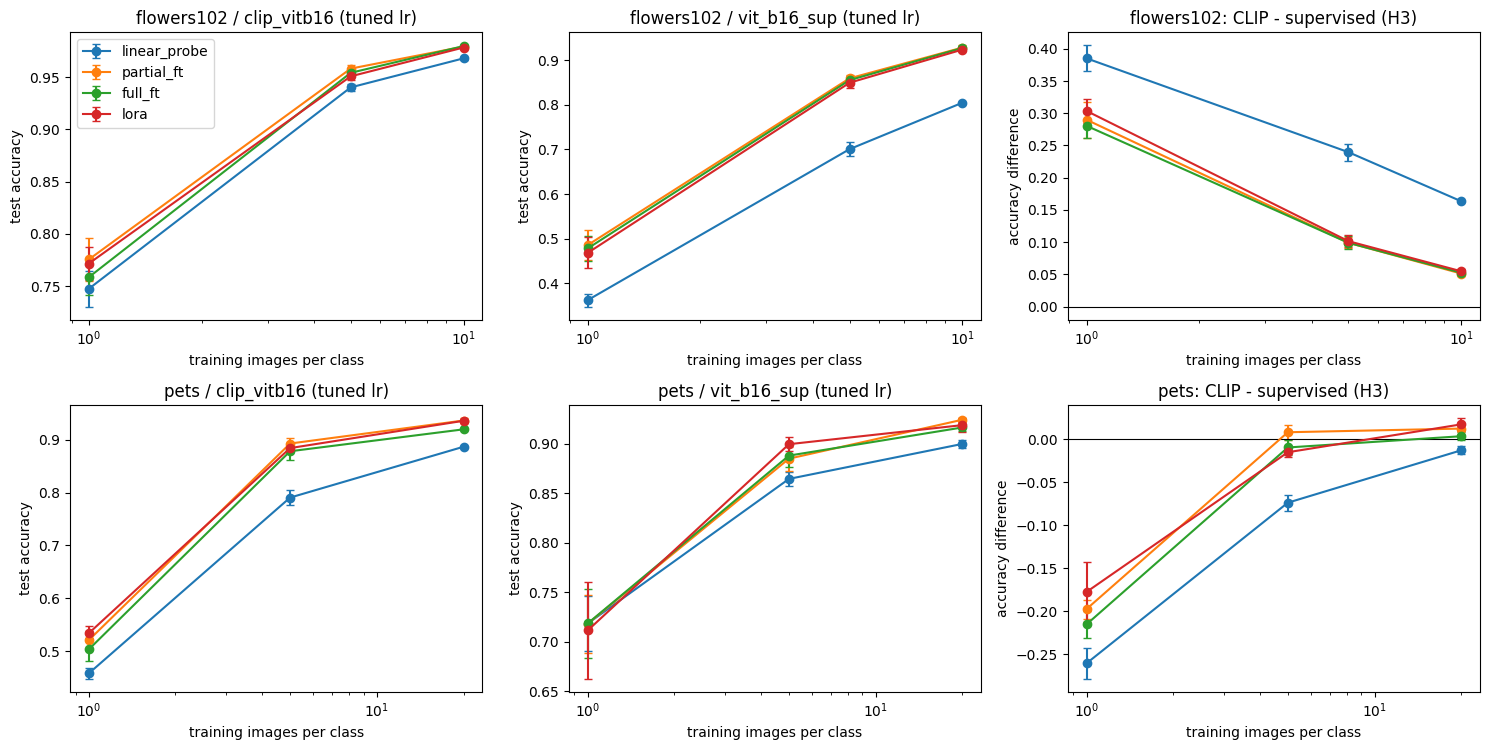

In [16]:
# Experiment 4 analysis: accuracy, paired differences (full FT vs the others, CLIP vs supervised) and selected learning rates per dataset.
def n_pos(x):
    return int((x > 0).sum())  # number of seeds with a positive difference

TUNED_FIN = {}
for ds_ in TUNED_SHOTS:
    t = TUNED[ds_].rows()
    if t.empty:
        continue
    best = best_lr(t, ['backbone', 'method', 'shots']).rename(columns={'lr': 'best_lr'})
    fin = selected_runs(t, ['backbone', 'method', 'shots'])  # test accuracy of the validation-selected lr, seeds 0-2
    TUNED_FIN[ds_] = fin
    piv = fin.pivot_table(index=['backbone', 'shots', 'seed'], columns='method', values='test_acc')
    print(f'===== {ds_}: test accuracy (mean, std over seeds) =====')
    display(fin.groupby(['backbone', 'shots', 'method']).test_acc.agg(['mean', 'std']).unstack('method').round(3))
    diffs = pd.concat({f'full_ft - {m}': piv.full_ft - piv[m] for m in METHODS if m != 'full_ft'}, axis=1)
    print('paired full FT - method (mean, std, seeds > 0):')
    display(diffs.groupby(['backbone', 'shots']).agg(['mean', 'std', n_pos]).round(3))
    gain = piv.loc['clip_vitb16'] - piv.loc['vit_b16_sup']  # same subset, same test set
    print('H3: CLIP - supervised (mean, std, seeds > 0):')
    display(gain.groupby('shots').agg(['mean', 'std', n_pos]).round(3))
    lr_tab = best.pivot_table(index=['backbone', 'shots'], columns='method', values='best_lr')
    edge = {m: (min(v[1]), max(v[1])) for m, v in TUNED_GRID.items()}
    on_edge = lr_tab.apply(lambda col: col.map(lambda x: np.isclose(x, edge[col.name][0]) or np.isclose(x, edge[col.name][1])))
    print(f'selected learning rates ({int(on_edge.values.sum())} of {on_edge.size} cells on the edge of the grid):')
    display(lr_tab)

if TUNED_FIN:
    fig, axes = plt.subplots(len(TUNED_FIN), 3, figsize=(15, 3.8 * len(TUNED_FIN)), squeeze=False)
    for r, (ds_, fin) in enumerate(TUNED_FIN.items()):
        for c, bb_ in enumerate(BACKBONES):
            for m in METHODS:
                g = fin[(fin.backbone == bb_) & (fin.method == m)].groupby('shots').test_acc.agg(['mean', 'std'])
                axes[r, c].errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3, label=m)
            axes[r, c].set(xscale='log', xlabel='training images per class', ylabel='test accuracy', title=f'{ds_} / {bb_} (tuned lr)')
        p = fin.pivot_table(index=['backbone', 'shots', 'seed'], columns='method', values='test_acc')
        for m in METHODS:
            d = (p.loc['clip_vitb16'][m] - p.loc['vit_b16_sup'][m]).groupby('shots').agg(['mean', 'std'])
            axes[r, 2].errorbar(d.index, d['mean'], d['std'], marker='o', capsize=3, label=m)
        axes[r, 2].axhline(0, color='k', lw=0.8)
        axes[r, 2].set(xscale='log', xlabel='training images per class', ylabel='accuracy difference', title=f'{ds_}: CLIP - supervised (H3)')
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()

#### Findings

Tuned protocol (learning rate chosen on validation, seed 0; 3 seeds; paired by seed) on Flowers102 (shots 1, 5, 10) and Oxford Pets (shots 1, 5, 20). Selected learning rates are on the edge of the grid in 4 of 48 cells, all for the supervised backbone with `partial_ft` (upper edge 3e-4 on Flowers102 at all three shot counts, lower edge 1e-6 on Pets at 1 image/class); no CLIP cell is on the edge. Exact validation ties at seed 0 (broken by grid order) occur in 1 of 24 cells on Flowers102 and 3 of 24 on Pets.

- **H1 (prediction confirmed in 13 of 16 cells; the three misses are linear-probe gaps smaller than predicted).**
  - *Linear probe:* below full FT in 7 of 8 dataset/backbone/shot cells at 1 and 5 images/class, positive on all seeds; full FT - linear probe is +0.011 and +0.014 for CLIP on Flowers102 (below the predicted 0.02), +0.045 and +0.088 for CLIP on Pets, +0.116 and +0.155 for the supervised backbone on Flowers102, and +0.024 for the supervised backbone on Pets at 5 images/class. The exception is the supervised backbone on Pets at 1 image/class (0.000 +- 0.007, a tie).
  - *LoRA:* full FT - LoRA is at most +0.010 in all 8 cells, and LoRA is clearly better than full FT for CLIP at 1 image/class (full FT - LoRA = -0.013 +- 0.006 on Flowers102, -0.031 +- 0.011 on Pets) and for the supervised backbone on Pets at 5 images/class (-0.012 +- 0.005).
- **H2 within this range (prediction confirmed).** Full FT - LoRA is at most +0.010 in all 12 cells (up to 10 images/class on Flowers102, 20 on Pets); there is no crossover, and at the largest size on Pets LoRA is clearly better for CLIP (-0.016 +- 0.001). Partial FT is within 0.01 of full FT for the supervised backbone in every cell; for CLIP it is clearly better than full FT at 1 image/class on both datasets (-0.017 and -0.018) and at 5 and 20 images/class on Pets (-0.015 and -0.017). This range says nothing about hundreds of images/class.
- **H3 (prediction confirmed on both datasets): the sign of the CLIP effect depends on the dataset.**
  - *Flowers102:* CLIP - supervised is positive on all three seeds for all four methods at every shot count: at 1 image/class +0.281 (full FT), +0.385 (linear probe), +0.304 (LoRA), +0.290 (partial FT); at 5 images/class +0.099, +0.240, +0.101, +0.099; at 10 images/class +0.052, +0.163, +0.055, +0.051. The advantage survives tuning, so the fixed-learning-rate result of the main study was not a tuning artefact.
  - *Pets:* the supervised backbone is better at 1 image/class (-0.215, -0.261, -0.178, -0.198; positive on none of the seeds). At 5 images/class it is still clearly better for the linear probe (-0.074) and LoRA (-0.015 +- 0.005), while full FT and partial FT tie (-0.010, +0.008); at 20 images/class CLIP is clearly better with LoRA (+0.017) and partial FT (+0.012), full FT ties (+0.003) and the CLIP linear probe is still behind (-0.013).


## 6. Ablations and robustness checks

Each ablation changes one factor of an experiment above and checks whether a conclusion depends on it. They are sensitivity analyses: none of them changed a hyperparameter of the experiments, and the tables of the experiments are left as they are.

| section | ablation of | question |
|---|---|---|
| 6.1 LoRA rank, unfrozen blocks, linear-probe budget | Experiment 1 (Flowers102, CLIP, 1 and 5 shots) | do the fixed choices (rank 8, 4 blocks, 100 steps, head lr 1e-3) limit a method? |
| 6.2 Training budget | Experiment 3 (CLIP, full FT and LoRA) | do "no crossover" and "full FT ~ LoRA" depend on the number of steps? |
| 6.3 Check 1: learning-rate selection | Experiment 3 | how much do the verdicts depend on the chosen learning rate? |
| 6.3 Check 2: extended learning-rate grid | Experiment 3 | do optima on the edge of the grid hide better learning rates? |
| 6.4 Logistic-regression probe | Experiments 3 and 4 (linear probe) | is the linear probe weak because of how it is trained? |

### 6.1 LoRA rank, unfrozen blocks and linear-probe budget

Scope: Flowers102, CLIP ViT-B/16, 1 and 5 shots, 3 seeds (same k-shot subsets as the main study). One factor is changed at a time; the reference value is the main-study run (LoRA rank 8, `PARTIAL_K` 4, linear probe 100+ steps with head lr 1e-3).

1. **LoRA rank** in {1, 2, 4, 8, 16}.
2. **Number of unfrozen blocks** `PARTIAL_K` in {1, 2, 4, 8, 12}; 12 = all transformer blocks, which differs from `full_ft` only in the patch and positional embeddings, the class token and (CLIP only) the pre-norm layer.
3. **Linear-probe budget** (sensitivity check for H1): 500 steps, or head lr 1e-2 instead of 1e-3.

These runs are a sensitivity analysis on the test set: they do not replace the fixed hyperparameters of the main study, and no value is selected from them.


In [17]:
# Ablation runs: one factor changed at a time on Flowers102 / CLIP / 1 and 5 shots; resumable, one CSV row per run.
ABLATION = RunLog('ablation')
ABL_DATASET, ABL_BACKBONE, ABL_SHOTS = 'flowers102', 'clip_vitb16', [1, 5]
# (study, method, hyperparameter of run_one, values to run); the main-study value of each factor is not re-run (taken from Experiment 1)
ABLATIONS = [
    ('lora_rank', 'lora', 'lora_rank', [1, 2, 4, 16]),
    ('partial_k', 'partial_ft', 'partial_k', [1, 2, 8, 12]),
    ('lp_min_steps', 'linear_probe', 'min_steps', [500]),
    ('lp_head_lr', 'linear_probe', 'head_lr', [1e-2]),
]
for (study, method, var, values), value, k, s in ((a, v, k, s) for a in ABLATIONS for v in a[3] for k in ABL_SHOTS for s in SEEDS):
    if not ABLATION.done(study=study, value=float(value), shots=k, seed=s):
        ABLATION.record(dict(study=study, method=method, value=value, shots=k, seed=s),
                        lambda: dict(test_acc=run_one(ABL_DATASET, ABL_BACKBONE, method, k, s, **{var: value})))

#### Reading the figure

**Left and centre:** accuracy against LoRA rank and against the number of unfrozen blocks (blue: 1 shot, orange: 5 shots); dashed and dotted lines are full FT and the linear probe of the main study at the same shots, and the x labels also give the trainable backbone parameters. **Right:** linear probe with a longer budget or a larger head learning rate, against the main-study probe; the dashed line is LoRA rank 8. The table lists mean, std and the paired difference (`delta`) with respect to the main-study value.


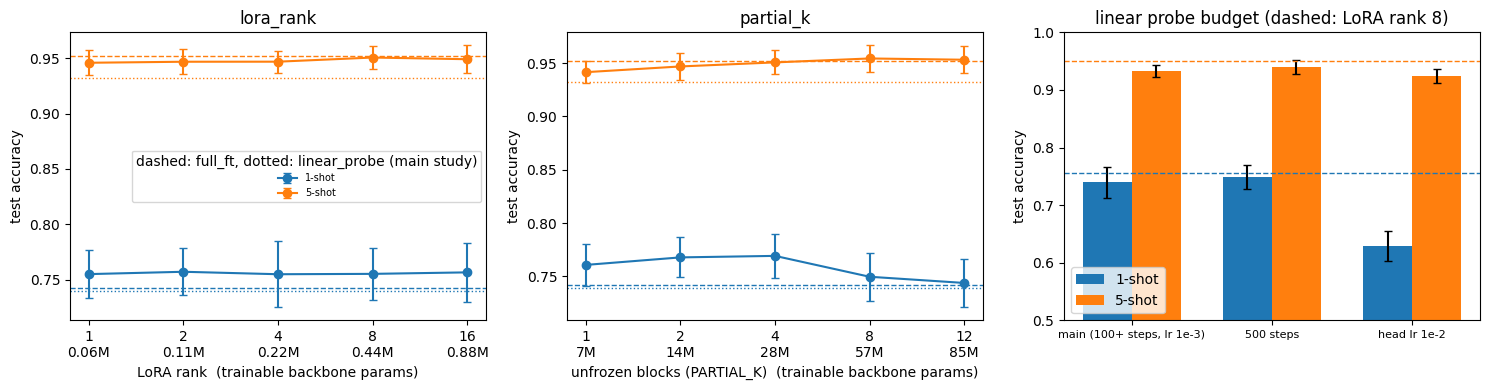

acc  acc_std  delta  delta_std
study        value   shots                                  
lora_rank    1.000   1      0.755    0.022 -0.000      0.003
                     5      0.946    0.011 -0.005      0.002
             2.000   1      0.757    0.021  0.002      0.003
                     5      0.947    0.011 -0.004      0.001
             4.000   1      0.755    0.030 -0.000      0.012
                     5      0.947    0.010 -0.004      0.002
             8.000   1      0.755    0.023  0.000      0.000
                     5      0.951    0.010  0.000      0.000
             16.000  1      0.757    0.027  0.001      0.007
                     5      0.949    0.012 -0.002      0.004
lp_head_lr   0.001   1      0.739    0.027  0.000      0.000
                     5      0.932    0.011  0.000      0.000
             0.010   1      0.629    0.026 -0.110      0.010
                     5      0.924    0.012 -0.008      0.001
lp_min_steps 100.000 1      0.739    0.027  0.000      0.000
                     5      0.932    0.011  0.000      0.000
             500.000 1      0.749    0.021  0.009      0.006
                     5      0.940    0.012  0.007      0.002
partial_k    1.000   1      0.761    0.020 -0.008      0.001
                     5      0.942    0.010 -0.009      0.003
             2.000   1      0.768    0.019 -0.001      0.002
                     5      0.947    0.013 -0.004      0.002
             4.000   1      0.769    0.021  0.000      0.000
                     5      0.951    0.011  0.000      0.000
             8.000   1      0.750    0.022 -0.020      0.009
                     5      0.954    0.012  0.004      0.002
             12.000  1      0.744    0.023 -0.025      0.010
                     5      0.953    0.012  0.002      0.001

In [18]:
# Ablation analysis: merge the ablation runs with the matching main-study runs and plot accuracy versus the changed factor.
abl = ABLATION.rows().drop(columns='time_s')
base = df[(df.dataset == ABL_DATASET) & (df.backbone == ABL_BACKBONE) & df.shots.isin([str(k) for k in ABL_SHOTS])]
# main-study value of each factor and the method it applies to (the reference point of every ablation)
REF = {'lora_rank': ('lora', LORA_RANK), 'partial_k': ('partial_ft', PARTIAL_K),
       'lp_min_steps': ('linear_probe', MIN_STEPS), 'lp_head_lr': ('linear_probe', HEAD_LR)}
ref_rows = [pd.DataFrame(dict(study=st, method=m, value=float(v), shots=base[base.method == m].shots.astype(int),
                              seed=base[base.method == m].seed, test_acc=base[base.method == m].test_acc))
            for st, (m, v) in REF.items()]
abl_all = pd.concat([abl] + ref_rows, ignore_index=True)
abl_all['value'] = abl_all.value.astype(float)

# paired difference w.r.t. the main-study value of the same study, seed and shot count
ref_acc = abl_all[abl_all.value == abl_all.study.map({s: float(v) for s, (m, v) in REF.items()})]
abl_all = abl_all.merge(ref_acc.rename(columns={'test_acc': 'ref_acc'})[['study', 'shots', 'seed', 'ref_acc']], on=['study', 'shots', 'seed'])
abl_all['delta'] = abl_all.test_acc - abl_all.ref_acc
tab = abl_all.groupby(['study', 'value', 'shots']).agg(acc=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
                                                       delta=('delta', 'mean'), delta_std=('delta', 'std')).round(3)

main_mean = lambda m, k: base[(base.method == m) & (base.shots == str(k))].test_acc.mean()
colors = {1: 'tab:blue', 5: 'tab:orange'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# panels 1-2: LoRA rank and number of unfrozen blocks, with full_ft (dashed) and linear_probe (dotted) of the main study as references
for ax, study, xlabel in zip(axes[:2], ['lora_rank', 'partial_k'], ['LoRA rank', 'unfrozen blocks (PARTIAL_K)']):
    for k in ABL_SHOTS:
        g = abl_all[(abl_all.study == study) & (abl_all.shots == k)].groupby('value').test_acc.agg(['mean', 'std'])
        ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, color=colors[k], label=f'{k}-shot')
        ax.axhline(main_mean('full_ft', k), color=colors[k], ls='--', lw=1)
        ax.axhline(main_mean('linear_probe', k), color=colors[k], ls=':', lw=1)
    ticks = g.index.astype(int)
    # x labels also show the trainable backbone parameters (55,296 per unit of LoRA rank; about 7.08M per transformer block)
    ax.set_xticks(range(len(g)), [f'{v}\n{55296 * v / 1e6:.2f}M' if study == 'lora_rank' else f'{v}\n{7.08 * v:.0f}M' for v in ticks])
    ax.set(xlabel=xlabel + '  (trainable backbone params)', ylabel='test accuracy', title=study)
axes[0].legend(title='dashed: full_ft, dotted: linear_probe (main study)', fontsize=7)

# panel 3: linear-probe budget (more steps or a larger head lr) against the main-study probe, with LoRA rank 8 as the dashed reference
lp = abl_all[abl_all.study.isin(['lp_min_steps', 'lp_head_lr'])]
variants = [('main (100+ steps, lr 1e-3)', None), ('500 steps', ('lp_min_steps', float(MIN_STEPS) * 5)), ('head lr 1e-2', ('lp_head_lr', 1e-2))]
w = 0.35
for i, k in enumerate(ABL_SHOTS):
    vals = [base[(base.method == 'linear_probe') & (base.shots == str(k))].test_acc if v is None
            else lp[(lp.study == v[0]) & (lp.value == v[1]) & (lp.shots == k)].test_acc for _, v in variants]
    axes[2].bar(np.arange(len(vals)) + (i - 0.5) * w, [x.mean() for x in vals], w, yerr=[x.std() for x in vals], capsize=3,
                color=colors[k], label=f'{k}-shot')
    axes[2].axhline(main_mean('lora', k), color=colors[k], ls='--', lw=1)
axes[2].set_xticks(range(len(variants)), [n for n, _ in variants], fontsize=8)
axes[2].set(ylabel='test accuracy', title='linear probe budget (dashed: LoRA rank 8)', ylim=(0.5, 1))
axes[2].legend()
plt.tight_layout()
plt.show()
tab


#### Findings

Flowers102, CLIP ViT-B/16, 3 seeds; differences are paired by seed with the main-study value.

- **LoRA rank is not a sensitive factor.** Accuracy is flat from rank 1 to 16 (1 shot: 0.755-0.757, rank 8: 0.755; 5 shots: 0.946-0.949, rank 8: 0.951); every change is at most 0.005 in absolute value, below the 0.01 tie threshold (ranks 1, 2 and 4 at 5 shots are lower on all three seeds, by 0.004-0.005). Rank 1 (about 55k trainable backbone parameters) is as good as rank 8, so the rank of the main study was not a limiting choice. The LoRA scale is `LORA_ALPHA / rank` with `LORA_ALPHA` fixed at 16, so this ablation changes the rank and the scale of the update together (scale 16 at rank 1, 1 at rank 16); it does not separate the two.
- **Unfreezing more blocks helps only with more data.** With 5 shots accuracy rises with the number of unfrozen blocks up to k=8 (k=1: 0.942, k=2: 0.947, k=4: 0.951, k=8: 0.954) and stays there at k=12 (0.953; `full_ft`: 0.952); k=1 is below k=4 on all seeds (-0.009 +- 0.003). With 1 shot the best values are k=2 and k=4 (0.768, 0.769), and k=8 and k=12 are lower on all three seeds by 0.020 +- 0.009 and 0.025 +- 0.010: with one image per class, adapting more than 4 blocks hurts.
- **The linear probe is mildly under-trained at the base budget, not badly.** 500 steps give +0.009 +- 0.006 (1 shot) and +0.007 +- 0.002 (5 shots), positive on all seeds but below 0.01; head lr 1e-2 is worse at 1 shot (-0.110) and about equal at 5 shots (-0.008). With 500 steps the probe stays below LoRA (1 shot: 0.749 vs 0.755; 5 shots: 0.940 vs 0.951).
- These runs are a sensitivity analysis on the test set. The main-study hyperparameters were not changed after seeing them.


### 6.2 Training budget (EuroSAT, CLIP)

**Why.** The budget of the scaling study is 10 epochs, with at least 100 and at most 1,500 optimizer steps. It is epoch-limited only at 1,500 images/class (about 3.2 epochs); at 100 and 500 images/class it is already about 10 epochs, and at 20 images/class the 100-step floor gives about 14 epochs. The verdicts "no crossover" and "full FT ~ LoRA" could therefore depend on the budget, especially for full FT with a small learning rate.

**Design (fixed before running).** CLIP ViT-B/16, `full_ft` and `lora`, the validation-selected learning rate of the scaling study (not re-tuned), seeds 0, 1, 2, same subsets. Step multiplier x2 and x4 at 20 images/class (200 and 400 steps) and x3 at 1,500 images/class (4,500 steps, about 9.6 epochs, i.e. the same number of epochs as at 500 images/class). The x1 reference is the scaling-study run with the same seed and learning rate.

**Prediction.** If the budget limits the comparison, accuracy at the longer budget rises clearly (more than about 0.005) and the full FT - LoRA difference changes sign or size. If not, accuracies and the difference stay within seed noise.


In [19]:
# Training-budget check: re-run full FT and LoRA on EuroSAT/CLIP with more optimizer steps at the already selected lr.
BUDGET = RunLog('budget_check_eurosat')
BUDGET_JOBS = [(20, 2), (20, 4), (1500, 3)]  # (images/class, step multiplier)
BUDGET_METHODS = ['full_ft', 'lora']

def budget_lr(method, shots):  # validation-selected lr of the scaling study (CLIP), not re-tuned
    d = SCALE['clip_vitb16'].rows()
    return float(best_lr(d[(d.method == method) & (d.shots == shots)], ['method', 'shots']).lr.iloc[0])

def run_budget(method, shots, factor, seed):
    # Scaling the epochs, the minimum steps and the step cap by the same factor multiplies the number of steps by that factor in every regime.
    return run_scaling('clip_vitb16', method, shots, budget_lr(method, shots), seed,
                       epochs=EPOCHS * factor, min_steps=MIN_STEPS * factor, max_steps=TUNED_MAX_STEPS * factor)

# Resumable loop over (shots, factor) x method x seed; the x1 reference is already in the log of Experiment 3.
for (shots_, factor_), method_, seed_ in itertools.product(BUDGET_JOBS, BUDGET_METHODS, SEEDS):
    keys = dict(method=method_, shots=shots_, factor=factor_, seed=seed_)
    if not BUDGET.done(**keys):
        BUDGET.record(dict(keys, lr=budget_lr(method_, shots_)), lambda: run_budget(method_, shots_, factor_, seed_))


In [20]:
# Budget-check analysis: accuracy and full FT - LoRA gap as a function of the step multiplier (needs FIN from the scaling analysis cell).
bud = BUDGET.rows()
# x1 reference = scaling-study runs of the same seeds and learning rates
ref = FIN['clip_vitb16'][FIN['clip_vitb16'].shots.isin([s for s, _ in BUDGET_JOBS]) & FIN['clip_vitb16'].method.isin(BUDGET_METHODS)]
ref = ref.assign(factor=1)[['method', 'shots', 'factor', 'seed', 'lr', 'val_acc', 'test_acc']]
allb = pd.concat([ref, bud[ref.columns]], ignore_index=True)

acc_b = allb.groupby(['shots', 'factor', 'method']).test_acc.agg(['mean', 'std']).unstack('method').round(3)
pv = allb.pivot_table(index=['shots', 'factor', 'seed'], columns='method', values='test_acc')
gap = (pv.full_ft - pv.lora).groupby(['shots', 'factor']).agg(['mean', 'std']).round(3)
# gain of each longer run over the x1 run of the same method, shots and seed (paired)
base_ = allb[allb.factor == 1].set_index(['method', 'shots', 'seed']).test_acc
allb['gain_vs_x1'] = allb.test_acc - allb.set_index(['method', 'shots', 'seed']).index.map(base_)
gain_b = allb.groupby(['shots', 'factor', 'method']).gain_vs_x1.agg(['mean', 'std']).unstack('method').round(3)
print('test accuracy (mean, std over seeds) by step multiplier:')
display(acc_b)
print('gain over the x1 budget (paired by seed):')
display(gain_b)
print('full FT - LoRA (paired by seed):')
display(gap)


test accuracy (mean, std over seeds) by step multiplier:


mean            std       
method       full_ft   lora full_ft   lora
shots factor                              
20    1        0.924  0.914   0.001  0.005
      2        0.924  0.922   0.008  0.011
      4        0.934  0.926   0.006  0.013
1500  1        0.983  0.980   0.001  0.004
      3        0.987  0.984   0.001  0.002

gain over the x1 budget (paired by seed):


mean            std       
method       full_ft   lora full_ft   lora
shots factor                              
20    1        0.000  0.000   0.000  0.000
      2        0.001  0.009   0.008  0.007
      4        0.010  0.012   0.005  0.008
1500  1        0.000  0.000   0.000  0.000
      3        0.004  0.004   0.001  0.002

full FT - LoRA (paired by seed):


mean    std
shots factor              
20    1       0.010  0.006
      2       0.002  0.016
      4       0.008  0.017
1500  1       0.002  0.003
      3       0.003  0.002

#### Findings

EuroSAT, CLIP ViT-B/16, same learning rates as the scaling study, mean +- std over 3 seeds; gains are paired by seed with the x1 run.

| images/class | steps multiplier | full FT | LoRA | full FT - LoRA |
|---|---|---|---|---|
| 20 | x1 (100) | 0.924 +- 0.001 | 0.914 +- 0.005 | +0.010 +- 0.006 |
| 20 | x2 (200) | 0.924 +- 0.008 | 0.922 +- 0.011 | +0.002 +- 0.016 |
| 20 | x4 (400) | 0.934 +- 0.006 | 0.926 +- 0.013 | +0.008 +- 0.017 |
| 1,500 | x1 (1,500) | 0.983 +- 0.001 | 0.980 +- 0.004 | +0.002 +- 0.003 |
| 1,500 | x3 (4,500) | 0.987 +- 0.001 | 0.984 +- 0.002 | +0.003 +- 0.002 |

- **At 1,500 images/class the budget is not limiting.** Three times more steps give +0.004 +- 0.001 (full FT) and +0.004 +- 0.002 (LoRA), positive on all seeds but below the 0.005 threshold of the prediction, and the difference between the methods stays at +0.003 +- 0.002.
- **At 20 images/class the budget limits the absolute accuracy, not the comparison.** With 4x the steps both methods gain about 0.01 on all seeds (full FT +0.010 +- 0.005, LoRA +0.012 +- 0.008), above the threshold; with 2x only LoRA gains (+0.009 +- 0.007). Full FT - LoRA moves from +0.010 +- 0.006 to +0.002 +- 0.016 (x2) and +0.008 +- 0.017 (x4): within the seed noise, so the marginal full-FT advantage at 20 images/class of the scaling study is not stable across budgets.
- **Conclusion.** The "full FT ~ LoRA" and "no crossover" verdicts hold at a longer budget. At 20 images/class the 100-step budget leaves about 0.01 of accuracy unused for both methods. The learning rates were not re-tuned for the longer runs (full FT used 3e-6, the lower edge of the grid, at both sizes), and only CLIP, full FT and LoRA were checked.


### 6.3 Robustness of the EuroSAT verdicts (Checks 1 and 2)

The verdicts rest on the EuroSAT scaling study, which has three weaknesses: (1) the dataset was chosen after the main-study results and it is a single, domain-shifted dataset; (2) the learning rates were tuned on a validation set that is larger than the training set below 20 images/class; (3) the selected learning rate sits on the edge of its grid in **27 of 48** (backbone, method, shots) cells, so the optimum may lie outside the grid. Weakness (1) is addressed by Experiment 4, (2) and (3) by the two checks below. **The design and predictions of Checks 1-2 and of Experiment 4 were written before any of their runs; the predictions are informed by the main study, which was already known.**

| check | addresses | new runs |
|---|---|---|
| Check 1. Sensitivity to the learning-rate choice | (2), (3) | none (seed-0 runs already in the logs) |
| Check 2. Extended grid on the edge cells | (3) | one learning rate beyond the edge per edge cell, seed 0; seeds 1-2 only if it wins on validation |

A verdict is called *robust* if the sign and the tie status (|difference| < 0.01) of the quantities behind it do not change.

#### Check 1: how much do the verdicts depend on the learning rate?

**Design.** For every (backbone, method, shots) the scaling study ran the 4 learning rates of the grid on seed 0. Four versions of the seed-0 test accuracy are compared: the validation-selected learning rate (the one used in the study), the mean over the grid (a "typical" learning rate), the worst learning rate, and the test-oracle (best test accuracy over the grid; optimistic, only a reference, never used for selection). The *regret* (oracle minus selected) measures how much the validation-based selection loses. The quantities checked are full FT - LoRA (H2) and CLIP - supervised (H3).

**Prediction.** (a) The regret is small (below 0.01) at 100 images/class and above, where the validation set is no longer larger than the training set, and larger at 1-5 images/class. (b) The "no crossover" verdict (|full FT - LoRA| < 0.01 from 100 images/class on) holds for the selected, grid-mean and oracle versions; the worst-lr version can differ because a single poor learning rate hurts one method more than the other. (c) The H3 differences keep their sign wherever they exceed 0.01 for the selected learning rate.

regret (oracle - selected test accuracy, seed 0):


method             full_ft  linear_probe   lora  partial_ft
            shots                                          
clip_vitb16 1        0.000         0.000  0.013       0.000
            5        0.000         0.000  0.006       0.005
            20       0.000         0.000  0.000       0.000
            100      0.000         0.000  0.003       0.000
            500      0.000         0.003  0.007       0.000
            1500     0.000         0.000  0.000       0.000
vit_b16_sup 1        0.000         0.011  0.000       0.000
            5        0.032         0.006  0.000       0.000
            20       0.000         0.010  0.005       0.000
            100      0.000         0.003  0.000       0.000
            500      0.000         0.000  0.001       0.000
            1500     0.002         0.001  0.000       0.000

cells with tied best validation accuracy (number of tied learning rates):


             shots  method      
clip_vitb16  500    lora            3
                    partial_ft      2
             1500   lora            2
vit_b16_sup  5      full_ft         2
             20     linear_probe    2
             100    linear_probe    2
Name: val_ties, dtype: int64

full FT - LoRA (seed 0) by learning-rate version:


clip_vitb16                                         vit_b16_sup  \
         selected grid_mean grid_median grid_worst oracle    selected   
shots                                                                   
1          -0.007     0.019      -0.053      0.201 -0.020       0.011   
5          -0.010     0.079      -0.035      0.403 -0.016      -0.021   
20          0.011     0.145      -0.007      0.584  0.011       0.004   
100         0.004     0.149       0.001      0.595  0.001       0.004   
500         0.006     0.201       0.003      0.802 -0.001       0.000   
1500        0.002     0.170       0.003      0.670  0.002      -0.001   

                                               
      grid_mean grid_median grid_worst oracle  
shots                                          
1        -0.003      -0.007     -0.009  0.011  
5         0.003      -0.004      0.007  0.011  
20       -0.005      -0.009      0.001 -0.001  
100       0.001       0.006     -0.011  0.004  
500       0.180       0.002      0.716 -0.000  
1500      0.185       0.003      0.734  0.001

CLIP - supervised (seed 0) by learning-rate version:


selected                                grid_mean                      \
method  full_ft linear_probe   lora partial_ft   full_ft linear_probe   lora   
shots                                                                          
1         0.076        0.061  0.095      0.052     0.040        0.052  0.018   
5         0.053        0.085  0.042      0.064    -0.013        0.073 -0.089   
20        0.017        0.067  0.010      0.018     0.010        0.052 -0.139   
100       0.001        0.017  0.001      0.002     0.003        0.005 -0.145   
500       0.000       -0.012 -0.005     -0.005    -0.001       -0.010 -0.022   
1500      0.003       -0.006  0.001     -0.006     0.000       -0.010  0.016   

                  grid_median                                grid_worst  \
method partial_ft     full_ft linear_probe   lora partial_ft    full_ft   
shots                                                                     
1           0.068       0.071        0.056  0.117      0.070     -0.060   
5           0.091       0.037        0.072  0.068      0.101     -0.147   
20          0.063       0.019        0.052  0.018      0.078     -0.015   
100         0.019       0.005        0.006  0.010      0.020      0.001   
500         0.002      -0.000       -0.010 -0.001      0.002     -0.002   
1500        0.001       0.002       -0.011  0.001      0.002     -0.004   

                                       oracle                                 
method linear_probe   lora partial_ft full_ft linear_probe   lora partial_ft  
shots                                                                         
1             0.048 -0.270      0.080   0.076        0.050  0.108      0.052  
5             0.072 -0.542      0.093   0.021        0.079  0.048      0.070  
20            0.048 -0.598      0.078   0.017        0.057  0.005      0.018  
100          -0.006 -0.606      0.033   0.001        0.014  0.004      0.002  
500          -0.011 -0.088      0.008   0.000       -0.009  0.001     -0.005  
1500         -0.013  0.060      0.007   0.001       -0.007  0.000     -0.006

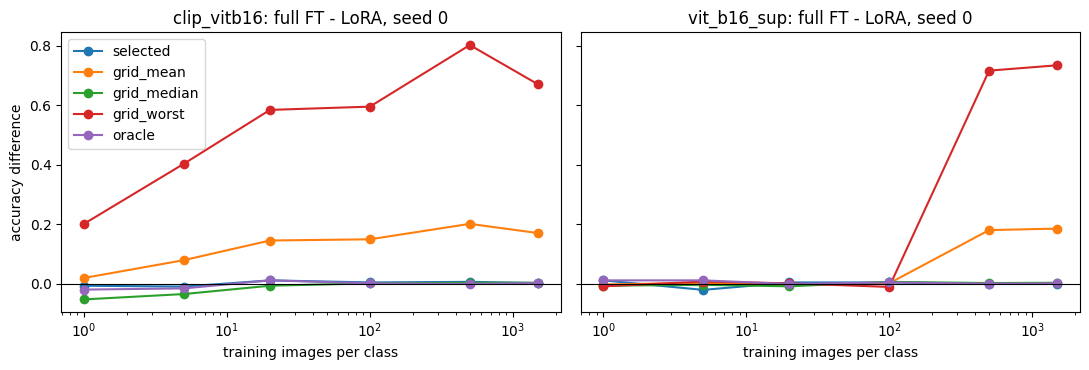

In [21]:
# Check 1: sensitivity of the verdicts to the learning-rate choice (EuroSAT, seed 0, existing runs only).
sens = {}
for bb_ in BACKBONES:
    s0_ = SCALE[bb_].rows()
    selected = best_lr(s0_, ['shots', 'method']).set_index(['shots', 'method']).test_acc  # validation-selected lr, as in the study
    s0_ = s0_[s0_.seed == 0]
    g_ = s0_.groupby(['shots', 'method'])
    # grid_median is robust to the diverged runs that dominate the grid mean and the worst lr (post hoc, see the findings)
    sens[bb_] = pd.DataFrame({'selected': selected, 'grid_mean': g_.test_acc.mean(), 'grid_median': g_.test_acc.median(),
                              'grid_worst': g_.test_acc.min(), 'oracle': g_.test_acc.max()})
    # cells where several learning rates share the best validation accuracy: the choice among them is arbitrary (first in the grid)
    sens[bb_]['val_ties'] = g_.val_acc.apply(lambda x: int((x == x.max()).sum()))
VARIANTS = ['selected', 'grid_mean', 'grid_median', 'grid_worst', 'oracle']

# regret of the validation-based selection: test accuracy lost with respect to the best learning rate of the grid
regret = pd.concat({bb: (d.oracle - d.selected).unstack('method') for bb, d in sens.items()}).round(3)
print('regret (oracle - selected test accuracy, seed 0):')
display(regret)
print('cells with tied best validation accuracy (number of tied learning rates):')
display(pd.concat({bb: d.val_ties[d.val_ties > 1] for bb, d in sens.items()}))

# H2: full FT - LoRA under the four versions of the learning-rate choice
gap_h2 = pd.concat({(bb, v): (d[v].unstack('method').full_ft - d[v].unstack('method').lora) for bb, d in sens.items() for v in VARIANTS}, axis=1).round(3)
print('full FT - LoRA (seed 0) by learning-rate version:')
display(gap_h2)

# H3: CLIP - supervised under the four versions
gap_h3 = pd.concat({v: (sens['clip_vitb16'][v] - sens['vit_b16_sup'][v]).unstack('method') for v in VARIANTS}, axis=1).round(3)
print('CLIP - supervised (seed 0) by learning-rate version:')
display(gap_h3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, bb_ in zip(axes, BACKBONES):
    for v in VARIANTS:
        ax.plot(gap_h2[(bb_, v)].index, gap_h2[(bb_, v)].values, marker='o', label=v)
    ax.axhline(0, color='k', lw=0.8)
    ax.set(xscale='log', xlabel='training images per class', title=f'{bb_}: full FT - LoRA, seed 0')
axes[0].set_ylabel('accuracy difference')
axes[0].legend()
plt.tight_layout()
plt.show()

#### Check 1 findings

Seed 0 of the EuroSAT scaling study, test accuracy at different versions of the learning-rate choice (the oracle uses the test set and is only a reference).

- **The validation-based selection loses little where the validation set is not larger than the training set (prediction a, confirmed).** Regret (oracle - selected) is at most 0.007 at 100 images/class and above (CLIP LoRA at 500, where three learning rates tie on validation) and 0 in 17 of those 24 cells. At 1-20 images/class it is larger in some cells: 0.032 (supervised full FT, 5 images, two learning rates tied on validation), 0.013 (CLIP LoRA, 1), 0.011 and 0.010 (supervised linear probe, 1 and 20). Six cells have tied best validation accuracies, broken by grid order.
- **"No crossover" does not depend on the selection (prediction b, partly confirmed).** From 100 images/class on, |full FT - LoRA| is below 0.01 with the selected learning rate (CLIP +0.004, +0.006, +0.002; supervised +0.004, 0.000, -0.001 at 100, 500, 1,500), with the test-oracle learning rate (at most 0.004) and with the median of the grid (at most 0.006). It does not hold for the grid *mean* (0.15-0.20 for CLIP at 100 images/class and above, 0.18-0.19 for the supervised backbone at 500 and 1,500) or for the worst learning rate: LoRA diverges at the largest learning rate of its grid (5e-3: test accuracy 0.17-0.34 for CLIP at every shot count and 0.24-0.25 for the supervised backbone at 500 and 1,500 images/class), while full FT degrades gracefully. I had predicted that the mean would hold and only the worst would differ, so that part of the prediction was wrong; the median version was added after this result was seen. These two versions measure how wide the stable learning-rate range of a method is, not how good the method is: LoRA has a narrower stable range than full FT, which is a practical difference but not an accuracy one.
- **H3 differences keep their sign (prediction c, confirmed).** Every CLIP - supervised difference with |difference| > 0.01 at the selected learning rate (all four methods at 1 and 5 images/class, full FT, partial FT and the linear probe at 20, the linear probe at 100 and 500) has the same sign with the grid median and with the oracle. The largest change is full FT at 5 images/class (+0.053 selected, +0.021 oracle): the supervised backbone has two learning rates tied on validation, the first one was kept and it is 0.03 worse on test. Only the grid mean and the worst learning rate change signs, again through LoRA's divergence.


#### Check 2: extended learning-rate grid on the edge cells

**Design.** In each cell where the validation-selected learning rate is the smallest or the largest of its grid, one more value is run beyond that edge (3x larger or 3x smaller: linear probe head lr 3e-2; `partial_ft` and `full_ft` 3e-4 or 1e-6; LoRA 1.5e-2 or 5e-5) on seed 0. If it beats the original choice on **validation** accuracy (strictly), seeds 1 and 2 are run at the new learning rate and it replaces the original one; otherwise the original choice stays (ties keep the original). The results go to separate CSVs, so the tables of the scaling study are left untouched and compared with the extended-grid version below. The new value can itself be on the new edge; no further extension is run.

**Prediction.** The extension changes the accuracy of most cells by less than 0.01. The exception is the supervised backbone with `partial_ft` (upper edge in all 6 shot counts), where a gain of 0.01-0.03 is plausible at low shots. The verdicts (no full FT - LoRA crossover, linear probe weakest, the sign of the CLIP - supervised differences) do not change sign.

In [22]:
# Check 2: one more learning rate beyond the grid edge for every edge cell of the scaling study; separate CSVs, resumable.
EXT = {bb: RunLog(f'scaling_eurosat_ext_{bb}') for bb in BACKBONES}

def edge_cells(bb):
    # cells whose validation-selected lr (seed 0, original grid) is the smallest or largest value of the grid:
    # (method, shots, original lr, original seed-0 validation accuracy, new lr beyond the edge)
    out = []
    for best in best_lr(SCALE[bb].rows(), ['method', 'shots']).itertuples():
        method, shots = best.method, best.shots
        lo, hi = min(SCALE_GRID[method][1]), max(SCALE_GRID[method][1])
        if np.isclose(best.lr, hi):
            new = float(f'{hi * 3:.2g}')
        elif np.isclose(best.lr, lo):
            new = float(f'{lo / 3:.2g}')
        else:
            continue
        out.append((method, int(shots), float(best.lr), float(best.val_acc), new))
    return out

def ext_find(bb, method, shots, lr, seed):
    return EXT[bb].find(method=method, shots=shots, lr=lr, seed=seed)

def ext_run(bb, method, shots, lr, seed):
    # same training and evaluation code as the scaling study
    EXT[bb].record(dict(method=method, shots=shots, lr=lr, seed=seed), lambda: run_scaling(bb, method, shots, lr, seed))

for bb_ in BACKBONES:
    for method_, shots_, lr0_, val0_, new_ in edge_cells(bb_):
        if ext_find(bb_, method_, shots_, new_, 0).empty:
            ext_run(bb_, method_, shots_, new_, 0)
        # the new lr replaces the original one only if it is strictly better on validation accuracy (seed 0)
        if ext_find(bb_, method_, shots_, new_, 0).val_acc.iloc[0] > val0_:
            for seed_ in SEEDS[1:]:
                if ext_find(bb_, method_, shots_, new_, seed_).empty:
                    ext_run(bb_, method_, shots_, new_, seed_)

In [23]:
# Check 2 analysis: edge cells before/after the extension, and the headline differences recomputed with the extended-grid selection.
rows = []
for bb_ in BACKBONES:
    for method_, shots_, lr0_, val0_, new_ in edge_cells(bb_):
        e_all = ext_find(bb_, method_, shots_, new_, 0)  # seed 0 of the extended lr
        won = bool(e_all.val_acc.iloc[0] > val0_)
        old = FIN[bb_][(FIN[bb_].method == method_) & (FIN[bb_].shots == shots_)].test_acc
        # test accuracy over seeds 0-2 of the extended lr (only available if it won on validation); otherwise the original choice stays
        new = pd.concat([ext_find(bb_, method_, shots_, new_, s) for s in SEEDS]).test_acc if won else old
        rows.append(dict(backbone=bb_, method=method_, shots=shots_, side='upper' if new_ > lr0_ else 'lower', lr_old=lr0_, lr_new=new_,
                         val_old=val0_, val_new=e_all.val_acc.iloc[0], won=won, test_old=old.mean(), test_new=new.mean()))
edge_tab = pd.DataFrame(rows).assign(delta=lambda d: d.test_new - d.test_old)
print(f'{len(edge_tab)} edge cells, extended lr wins on validation in {int(edge_tab.won.sum())}; mean test change over all edge cells {edge_tab.delta.mean():+.4f}, over winners {edge_tab[edge_tab.won].delta.mean():+.4f}')
display(edge_tab.round({'val_old': 3, 'val_new': 3, 'test_old': 3, 'test_new': 3, 'delta': 3}))

def seed_acc(bb, use_ext):
    # test accuracy by seed of every (method, shots) cell at the selected lr; with use_ext the winning extended lrs replace the original ones
    acc = {(m, k): g.set_index('seed').test_acc for (m, k), g in FIN[bb].groupby(['method', 'shots'])}
    if use_ext:
        ext = EXT[bb].rows()
        for r in edge_tab[(edge_tab.backbone == bb) & edge_tab.won].itertuples():
            e = ext[(ext.method == r.method) & (ext.shots == r.shots) & np.isclose(ext.lr.astype(float), r.lr_new)]
            acc[(r.method, r.shots)] = e.set_index('seed').test_acc
    return acc

def headline(use_ext):
    A = {bb: seed_acc(bb, use_ext) for bb in BACKBONES}
    out = {}
    for bb in BACKBONES:
        for k in SCALE_SHOTS:
            for m in ('linear_probe', 'partial_ft', 'lora'):
                out[(f'full_ft - {m}', bb, k)] = (A[bb][('full_ft', k)] - A[bb][(m, k)]).mean()
    for m in METHODS:
        for k in SCALE_SHOTS:
            out[(f'CLIP - sup, {m}', 'both', k)] = (A['clip_vitb16'][(m, k)] - A['vit_b16_sup'][(m, k)]).mean()
    return pd.Series(out)

cmp_ext = pd.DataFrame({'original': headline(False), 'extended': headline(True)}).assign(change=lambda d: d.extended - d.original)
flip = cmp_ext[(np.sign(cmp_ext.original) != np.sign(cmp_ext.extended)) & ((cmp_ext.original.abs() >= 0.01) | (cmp_ext.extended.abs() >= 0.01))]
tie_change = cmp_ext[(cmp_ext.original.abs() < 0.01) != (cmp_ext.extended.abs() < 0.01)]
print(f'{len(cmp_ext)} paired differences; largest change {cmp_ext.change.abs().max():.3f}; sign flips with |diff| >= 0.01: {len(flip)}; tie status changes: {len(tie_change)}')
print('differences that change by more than 0.01:')
display(cmp_ext[cmp_ext.change.abs() > 0.01].round(3))
print('full FT - LoRA, original vs extended grid:')
display(cmp_ext.loc['full_ft - lora'].round(3))

27 edge cells, extended lr wins on validation in 4; mean test change over all edge cells +0.0024, over winners +0.0161


,backbone,method,shots,side,lr_old,lr_new,val_old,val_new,won,test_old,test_new,delta
0,clip_vitb16,full_ft,1,lower,0.000003,0.000001,0.684,0.680,False,0.634,0.634,0.000
1,clip_vitb16,full_ft,5,lower,0.000003,0.000001,0.842,0.839,False,0.836,0.836,0.000
2,clip_vitb16,full_ft,20,lower,0.000003,0.000001,0.938,0.924,False,0.924,0.924,0.000
3,clip_vitb16,full_ft,100,lower,0.000003,0.000001,0.967,0.960,False,0.959,0.959,0.000
4,clip_vitb16,full_ft,1500,lower,0.000003,0.000001,0.980,0.974,False,0.983,0.983,0.000
5,clip_vitb16,linear_probe,1,upper,0.010000,0.030000,0.573,0.474,False,0.529,0.529,0.000
6,clip_vitb16,linear_probe,5,upper,0.010000,0.030000,0.799,0.774,False,0.761,0.761,0.000
7,clip_vitb16,linear_probe,100,upper,0.010000,0.030000,0.931,0.928,False,0.909,0.909,0.000
8,clip_vitb16,linear_probe,1500,upper,0.010000,0.030000,0.944,0.947,True,0.942,0.941,-0.001
9,clip_vitb16,lora,5,lower,0.000150,0.000050,0.856,0.845,False,0.839,0.839,0.000


60 paired differences; largest change 0.030; sign flips with |diff| >= 0.01: 2; tie status changes: 4
differences that change by more than 0.01:


original  extended  change
full_ft - partial_ft   vit_b16_sup 1     0.029    -0.001  -0.030
                                   5    -0.005    -0.034  -0.029
CLIP - sup, partial_ft both        1     0.010    -0.020  -0.030
                                   5     0.040     0.011  -0.029

full FT - LoRA, original vs extended grid:


original  extended  change
clip_vitb16 1       -0.031    -0.031     0.0
            5       -0.003    -0.003     0.0
            20       0.010     0.010     0.0
            100      0.003     0.003     0.0
            500      0.002     0.002     0.0
            1500     0.002     0.002     0.0
vit_b16_sup 1        0.000     0.000     0.0
            5       -0.031    -0.031     0.0
            20      -0.003    -0.003     0.0
            100     -0.001    -0.001     0.0
            500      0.002     0.002     0.0
            1500     0.001     0.001     0.0

#### Check 2 findings

EuroSAT, the 27 cells whose validation-selected learning rate was on the edge of the grid, one more value beyond the edge (seed 0).

- **The extended learning rate wins on validation in 4 of 27 cells.** Supervised `partial_ft` at 1, 5 and 20 images/class (3e-4; test +0.030, +0.029, +0.007) and the CLIP linear probe at 1,500 images/class (3e-2; validation +0.003, test -0.001). In the other 23 cells the original choice stays: the smaller full-FT learning rate (1e-6) is worse on validation in all 5 CLIP cells, and LoRA at 1.5e-2 diverges for the supervised backbone (validation 0.165-0.181). `full_ft` and `lora` are untouched by the extension in every cell.
- **Prediction, as written:** the mean change over the edge cells is small (+0.002) and the exceptions are the supervised `partial_ft` cells at low shots, as predicted. The part "no verdict changes sign" was not confirmed: 2 paired differences with |difference| >= 0.01 change sign, both involving supervised partial FT: full FT - partial FT at 1 image/class (+0.029 -> -0.001; at 5 images/class the difference goes from -0.005 to -0.034) and CLIP - supervised for partial FT at 1 image/class (+0.010 -> -0.020; at 5 images/class +0.040 -> +0.011); 4 differences change tie status in total.
- **What does not change.** Full FT - LoRA is identical in every cell, so "no crossover" is unaffected; the linear probe stays the weakest method; CLIP - supervised for full FT, LoRA and the linear probe is unchanged. **What changes** is the partial-FT story for the supervised backbone: the gap to full FT of +0.029 at 1 image/class was an artefact of the grid edge, and with the extended value partial FT is as good as (1 image) or better than (5 images) full FT; the CLIP advantage for partial FT disappears at 1 image/class and shrinks to +0.011 at 5. The tables of the scaling study above were left as they were (original grid); the Discussion quotes these corrections where they matter.


### 6.4 Linear probe with logistic regression on frozen features

**Why.** The linear probe of the experiments is trained like the other methods: AdamW on augmented images, at most 1,500 steps, head learning rate from a 4-value grid (on EuroSAT often at its upper edge). With 1,500 images/class its EuroSAT accuracy (0.942 for CLIP, 0.946 for the supervised backbone) is well below the 97.1 that the CLIP paper reports for a logistic-regression probe on CLIP ViT-B/16 features (Table 10). The verdict "the linear probe is the weakest method and its gap never closes" may therefore partly reflect how the probe was trained rather than the frozen features.

**Design (fixed before running, after the results of Experiments 3 and 4 were known).** The protocol of the CLIP paper (App. A.3): features before the projection (the class-token output after the final norm, `num_classes=0` in timm), computed once with the evaluation transform for the training images too (no augmentation); scikit-learn's L-BFGS logistic regression with at most 1,000 iterations; the L2 strength lambda (C = 1/lambda in scikit-learn) searched on the validation set from {1e-6, 1e-4, ..., 1e6} and then by halving the interval around the best value down to 8 steps per decade. Same splits, shot counts and k-shot subsets as Experiments 3 (EuroSAT) and 4 (Flowers102, Pets); lambda chosen on seed 0 and used for seeds 1 and 2, as in the tuned protocol; both backbones.

**Prediction.** On EuroSAT the logistic-regression probe is better than the AdamW probe from 100 images/class on, and its gap to full FT at 1,500 images/class is below 0.02; at 1 and 5 images/class it is still clearly below full FT and LoRA, so the linear-probe half of H1 stays rejected.

In [24]:
# 6.4: logistic-regression probe on frozen features (protocol of the CLIP paper, App. A.3) on the splits of Experiments 3 and 4.
from sklearn.linear_model import LogisticRegression
LBFGS = RunLog('lbfgs_probe')
LBFGS_SHOTS = {'eurosat': SCALE_SHOTS, **TUNED_SHOTS}
_FEATS = {}

def pool_eval_set(name):
    # the training pool of the split, with the evaluation transform (uint8), in pool order
    split = eurosat(BACKBONES[0])[0] if name == 'eurosat' else tuned_data(name, BACKBONES[0])[0]
    if name == 'eurosat':
        ds = torchvision.datasets.ImageFolder(DATA_ROOT / 'eurosat' / 'EuroSAT_RGB',
                                              transform=T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.PILToTensor()]))
    elif name == 'flowers102':
        ds = torchvision.datasets.Flowers102(DATA_ROOT / name, split='train', transform=EVAL_TF_U8)
    else:
        ds = torchvision.datasets.OxfordIIITPet(DATA_ROOT / name, split='trainval', transform=EVAL_TF_U8)
    return split, Subset(ds, split['pool'].tolist())

@torch.no_grad()
def frozen_features(name):
    """Features (class token after the final norm) of pool, validation and test images for both backbones, computed once."""
    if name not in _FEATS:
        split, pool = pool_eval_set(name)
        models = {bb: timm.create_model(TIMM_NAME[bb], pretrained=True, num_classes=0).to(DEVICE).eval() for bb in BACKBONES}
        norm = {bb: [torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM[bb]] for bb in BACKBONES}
        def feats(batches):
            out = {bb: [] for bb in BACKBONES}
            for x in batches:
                x = x.to(DEVICE).float() / 255
                for bb, m in models.items():
                    out[bb].append(m((x - norm[bb][0]) / norm[bb][1]).float().cpu())
            return {bb: torch.cat(v).numpy() for bb, v in out.items()}
        tensor_batches = lambda x: (x[i:i + 128] for i in range(0, len(x), 128))
        F_pool = feats(x for x, _ in DataLoader(pool, batch_size=128, num_workers=NUM_WORKERS))
        F_val, F_test = feats(tensor_batches(split['val'][0])), feats(tensor_batches(split['test'][0]))
        y = dict(pool=split['labels'][split['pool']], val=split['val'][1].numpy(), test=split['test'][1].numpy())
        _FEATS[name] = {bb: dict(pool=F_pool[bb], val=F_val[bb], test=F_test[bb]) for bb in BACKBONES}, y
        del models
    return _FEATS[name]

def lbfgs_fit(F, y, idx, log_lam):
    clf = LogisticRegression(C=10.0 ** -log_lam, max_iter=1000).fit(F['pool'][idx], y['pool'][idx])
    return dict(val_acc=clf.score(F['val'], y['val']), test_acc=clf.score(F['test'], y['test']))

def lambda_search(fit):
    # CLIP's parametric binary search: lambda in {1e-6, 1e-4, ..., 1e6}, then halve the interval around the peak to 8 steps per decade
    val = {}
    for x in range(-6, 7, 2):
        val[x] = fit(x)['val_acc']
    step = 2.0
    while step > 1 / 8:
        step /= 2
        best = max(val, key=val.get)
        for x in (best - step, best + step):
            if -6 <= x <= 6 and x not in val:
                val[x] = fit(x)['val_acc']
    return max(val, key=val.get)

for name, shots_list in LBFGS_SHOTS.items():
    for bb_ in BACKBONES:
        for shots_ in shots_list:
            keys = dict(dataset=name, backbone=bb_, shots=shots_)
            if all(LBFGS.done(**keys, seed=s) for s in SEEDS):
                continue
            feats_, y_ = frozen_features(name)
            idx_ = {s: few_shot_indices(y_['pool'], shots_, s) for s in SEEDS}
            log_lam = lambda_search(lambda x: lbfgs_fit(feats_[bb_], y_, idx_[0], x))  # selection on seed 0, validation only
            for s in SEEDS:
                if not LBFGS.done(**keys, seed=s):
                    LBFGS.record(dict(keys, seed=s, log10_lambda=log_lam), lambda: lbfgs_fit(feats_[bb_], y_, idx_[s], log_lam))

In [25]:
# 6.4 analysis: logistic-regression probe against the AdamW probe, LoRA and full FT of Experiments 3 and 4 (same subsets, paired by seed).
lb = LBFGS.rows()
EXP_FIN = {'eurosat': {bb: FIN[bb] for bb in BACKBONES},
           **{ds: {bb: TUNED_FIN[ds][TUNED_FIN[ds].backbone == bb] for bb in BACKBONES} for ds in TUNED_SHOTS}}
rows = []
for (name, bb, shots), g in lb.groupby(['dataset', 'backbone', 'shots']):
    f = EXP_FIN[name][bb]
    by_seed = {m: f[(f.method == m) & (f.shots == shots)].set_index('seed').test_acc for m in METHODS}
    probe = g.set_index('seed').test_acc
    row = dict(dataset=name, backbone=bb, shots=shots, lbfgs_probe=probe.mean(), adamw_probe=by_seed['linear_probe'].mean(),
               lora=by_seed['lora'].mean(), full_ft=by_seed['full_ft'].mean(), log10_lambda=g.log10_lambda.iloc[0])
    for m in ('full_ft', 'lora'):
        d = by_seed[m] - probe
        row.update({f'{m} - lbfgs': d.mean(), f'{m} - lbfgs std': d.std(), f'{m} - lbfgs seeds > 0': int((d > 0).sum())})
    d = probe - by_seed['linear_probe']
    row.update({'lbfgs - adamw': d.mean(), 'lbfgs - adamw std': d.std(), 'lbfgs - adamw seeds > 0': int((d > 0).sum())})
    rows.append(row)
probe_tab = pd.DataFrame(rows).set_index(['dataset', 'backbone', 'shots'])
display(probe_tab.round(3))

lbfgs_probe  adamw_probe   lora  full_ft  \
dataset    backbone    shots                                             
eurosat    clip_vitb16 1            0.565        0.529  0.665    0.634   
                       5            0.784        0.761  0.839    0.836   
                       20           0.881        0.850  0.914    0.924   
                       100          0.922        0.909  0.956    0.959   
                       500          0.946        0.931  0.975    0.977   
                       1500         0.960        0.942  0.980    0.983   
           vit_b16_sup 1            0.509        0.497  0.602    0.602   
                       5            0.714        0.706  0.802    0.771   
                       20           0.828        0.796  0.913    0.910   
                       100          0.902        0.901  0.959    0.958   
                       500          0.936        0.940  0.975    0.978   
                       1500         0.953        0.946  0.980    0.981   
flowers102 clip_vitb16 1            0.734        0.748  0.772    0.759   
                       5            0.934        0.940  0.951    0.954   
                       10           0.960        0.968  0.978    0.980   
           vit_b16_sup 1            0.380        0.362  0.468    0.478   
                       5            0.706        0.700  0.849    0.855   
                       10           0.801        0.804  0.923    0.927   
pets       clip_vitb16 1            0.454        0.458  0.534    0.503   
                       5            0.768        0.791  0.884    0.878   
                       20           0.883        0.887  0.936    0.920   
           vit_b16_sup 1            0.708        0.718  0.711    0.718   
                       5            0.853        0.865  0.900    0.888   
                       20           0.887        0.900  0.919    0.917   

                              log10_lambda  full_ft - lbfgs  \
dataset    backbone    shots                                  
eurosat    clip_vitb16 1             0.500            0.069   
                       5            -0.750            0.052   
                       20           -1.000            0.042   
                       100           0.500            0.037   
                       500          -0.250            0.031   
                       1500          0.500            0.023   
           vit_b16_sup 1            -6.000            0.093   
                       5            -1.000            0.058   
                       20            2.000            0.082   
                       100           0.000            0.056   
                       500          -1.625            0.041   
                       1500         -1.000            0.028   
flowers102 clip_vitb16 1             2.000            0.025   
                       5             0.000            0.020   
                       10           -1.000            0.020   
           vit_b16_sup 1             2.250            0.099   
                       5            -0.875            0.149   
                       10           -0.250            0.126   
pets       clip_vitb16 1             2.875            0.050   
                       5            -2.000            0.110   
                       20           -0.875            0.037   
           vit_b16_sup 1             1.500            0.010   
                       5            -6.000            0.035   
                       20           -6.000            0.029   

                              full_ft - lbfgs std  full_ft - lbfgs seeds > 0  \
dataset    backbone    shots                                                   
eurosat    clip_vitb16 1                    0.073                          3   
                       5                    0.012                          3   
                       20                   0.005                          3   
                       100                  0.004                 

#### Findings

Logistic-regression (L-BFGS) probe on frozen features against the AdamW probe, LoRA and full FT of Experiments 3 and 4, same subsets, paired by seed.

- **EuroSAT, CLIP: the L-BFGS probe is better than the AdamW probe at every size** (+0.023 to +0.036 at 1-20 images/class, the 1-image value with one negative seed; +0.013 +- 0.009, +0.015 +- 0.001 and +0.018 +- 0.002 at 100, 500 and 1,500, positive on all seeds), and reaches 0.960 at 1,500 images/class. **For the supervised backbone the gain is not consistent**: +0.032 at 20 images/class and +0.007 at 1,500, but +0.001 at 100 and -0.004 at 500. The prediction "better than the AdamW probe from 100 images/class on" holds for CLIP only.
- **The gap to full FT at 1,500 images/class shrinks but stays above 0.02** (CLIP 0.023 +- 0.001 instead of 0.041; supervised 0.028 +- 0.002 instead of 0.034), so that part of the prediction was not confirmed. The CLIP value (0.960) is still 1.1 points below the 97.1 of the CLIP paper, whose split and training-set size differ.
- **At 1 and 5 images/class the probe stays below full FT and LoRA on all seeds** (5 images/class: full FT - L-BFGS +0.052 +- 0.012 for CLIP and +0.058 +- 0.013 for the supervised backbone; at 1 image/class the differences are positive on all seeds but smaller than their std), as predicted: the linear-probe half of H1 stays rejected.
- **Flowers102 and Pets: no gain.** L-BFGS minus AdamW is between -0.023 and +0.017; it is negative on all seeds in 9 of the 12 cells, and positive on all seeds only for the supervised backbone on Flowers102 at 1 and 5 images/class (+0.017, +0.005). The AdamW probe of Experiment 4 is not handicapped on these datasets.
- The selected L2 strength sits at the lower end of the search range (lambda = 1e-6, i.e. almost no regularisation) in 3 of 24 cells (supervised backbone: EuroSAT at 1 image/class, Pets at 5 and 20).
- **Conclusion.** On EuroSAT with CLIP features, how the probe is trained explains about 0.02 of its gap to full FT; it does not explain the rest, nor the gap on Flowers102 and Pets. The verdict "the linear probe is the weakest method" holds with the probe protocol of the CLIP paper too.


## 7. Results and discussion

For each hypothesis: expected outcome, observed outcome, explanation. **The verdicts rest on the experiments with tuned learning rates:** the EuroSAT scaling study (Experiment 3; both backbones, 1 to 1,500 images/class, learning rate tuned per method and shot count on a validation set, 3 seeds, differences paired by seed) and the same protocol on Flowers102 and Oxford Pets (Experiment 4; up to 10 and 20 images/class). EuroSAT was added after seeing the main-study results (post hoc), because Flowers102 and Pets are too small to test H2 and the main study used untuned learning rates (see Experiment 3); Experiment 4 was added so that the verdicts do not rest on that choice alone. The Flowers102/Oxford Pets experiment with fixed, untuned learning rates (Experiment 1) is kept as exploratory evidence (subsection below), because tuning changes the accuracy of the fine-tuning methods at 1-20 images/class by up to +0.08 for the supervised backbone and up to about +0.03 for CLIP.

- **H1 (1-5 shots: linear probe and LoRA >= full FT). Half confirmed: LoRA yes, linear probe no.**
  - *LoRA:* across the 12 low-shot cells of the tuned experiments (Flowers102 and Pets at 1 and 5 images/class, EuroSAT at 1 and 5, both backbones) LoRA is never below full FT beyond the tie threshold, and it is clearly better in 5: CLIP at 1 image/class on all three datasets (full FT - LoRA = -0.013 on Flowers102, -0.031 on Pets, -0.031 on EuroSAT) and the supervised backbone at 5 images/class on Pets (-0.012) and EuroSAT (-0.031).
  - *Linear probe:* clearly below full FT in 11 of the 12 cells (by +0.011 to +0.155 on Flowers102 and Pets, +0.066 to +0.106 on EuroSAT, positive on all seeds); the exception is the supervised backbone on Pets at 1 image/class (0.000 +- 0.007, a tie). A probe trained like the CLIP paper's (logistic regression on frozen features, section 6.4) does not change this.
  - *Interpretation.* The two halves of H1 test different mechanisms. LoRA adapts the backbone with about 0.4M parameters; the linear probe cannot change the features, so its accuracy is bounded by how linearly separable the classes already are in the frozen feature space. It is close to full FT where the pre-trained features already separate the classes (CLIP on Flowers102: -0.011 at 1 image/class) and far from it where they do not (the supervised backbone on Flowers102, CLIP on Pets, both backbones on EuroSAT). The "(which overfits)" part of H1 was not tested: no training curves were recorded, so the low-shot deficit of full FT is not attributed to overfitting here.
  - *Partial FT* (not part of H1) depends on the dataset: for CLIP it is clearly better than full FT at 1 image/class on Flowers102 and Pets (-0.017, -0.018) but clearly worse on EuroSAT (+0.052), where adapting only the last 4 blocks to satellite images is not enough.
- **H2 (more data: full FT catches up and overtakes, crossover). Catch-up observed, overtaking not.**
  - With LoRA: for CLIP on EuroSAT, full FT - LoRA goes from -0.031 at 1 image/class to between -0.003 and +0.010 from 20 images/class on; the only positive values with the same sign on all seeds are +0.010 +- 0.006 at 20 images/class (at the tie threshold) and +0.003 +- 0.002 at 100. With 2x and 4x the steps the 20-image value drops to +0.002 +- 0.016 and +0.008 +- 0.017 (section 6.2), and with 3x the steps at 1,500 images/class it is +0.003 +- 0.002. For the supervised backbone the difference is within +-0.003 from 20 images/class on. The methods that adapt the backbone converge instead of full FT pulling ahead (100 images/class: 0.949-0.959 for CLIP, 0.953-0.959 for the supervised backbone; 1,500: 0.978-0.983 and 0.980-0.982). On Flowers102 and Pets (up to 10 and 20 images/class) full FT - LoRA is at most +0.010 in all 12 cells, and LoRA is clearly better for CLIP on Pets at 20 images/class (-0.016).
  - With partial FT: for CLIP on EuroSAT full FT is ahead at every size but the gap shrinks from +0.052 to +0.005; for the supervised backbone the gap of +0.029 at 1 image/class is a grid-edge artefact (Check 2: -0.001 with the extended grid, and -0.034 at 5 images/class), so partial FT is as good as full FT there.
  - With the linear probe: the gap shrinks (CLIP 0.106 to 0.041, supervised 0.105 to 0.034 from 1 to 1,500 images/class; 0.023 and 0.028 at 1,500 with the logistic-regression probe) but never closes. This is "full FT stays ahead", not a crossover.
  - Caveat: at 500-1,500 images/class every adapted method is at 0.972-0.983 on a 4,000-image test set (standard error about 0.002), so a ceiling effect may hide a crossover. The study does not exclude one with a harder dataset or much more data.
- **H3 (CLIP better than supervised features in low-shot). Dataset-dependent: confirmed on Flowers102 and on EuroSAT at 5-20 images/class, reversed on Pets at 1-5 images/class.**
  - *Flowers102 (Experiment 4):* CLIP is better for all four methods on all seeds at every shot count: +0.28 to +0.39 at 1 image/class, +0.10 to +0.24 at 5, +0.05 to +0.16 at 10. The advantage survives tuning.
  - *Pets (Experiment 4):* the supervised backbone is better at 1 image/class (-0.18 to -0.26, all seeds) and at 5 images/class for the linear probe (-0.074) and LoRA (-0.015); full FT and partial FT tie at 5; at 20 images/class CLIP is slightly ahead with LoRA (+0.017) and partial FT (+0.012), and still behind with the linear probe (-0.013).
  - *EuroSAT (Experiment 3):* under matched conditions (same subsets, seeds, test set, budget, tuning rule, and no text tower for either backbone) CLIP is ahead at 5 images/class for all four methods on all seeds (+0.036 to +0.065) and at 20 for full FT (+0.014) and the linear probe (+0.054); at 1 image/class the means are positive but one seed in three is negative for every method; from 100 images/class the backbones are equal. Check 1 shows that these signs do not depend on the learning-rate choice; Check 2 shrinks the partial-FT advantage at 5 images/class to +0.011 and reverses it at 1 image/class once the supervised backbone gets one more learning rate.
  - *Interpretation, not tested directly:* the datasets differ in how close they are to each pre-training. Only 1 of the 102 Flowers102 species is an ImageNet-1k class (artichoke; 3 more have a related class), while CLIP's web-scale pre-training very likely contains flowers; 24 of the 37 Pets breeds are ImageNet-1k classes (22 of the 25 dog breeds, all but American Bulldog, Havanese and Shiba Inu, and 2 of the 12 cat breeds, Persian and Siamese), so for most of Pets the supervised features were trained on those very labels; EuroSAT is far from both, and CLIP's advantage there is limited to 5-20 images/class and disappears once there are enough labels for either backbone. The CLIP paper attributes dataset-specific differences between CLIP and ImageNet features to the amount of relevant supervision in each pre-training set (see "Do the published papers support my hypotheses?"), which supports the mechanism but not these specific premises.
  - *Per-class check on Pets (post hoc; design and prediction written before the runs; the code is not part of this notebook).* The 48 Experiment 4 runs on Pets at 1 and 5 images/class were repeated at their selected learning rates, saving the per-class test predictions (the overall accuracies match the logged ones exactly). Prediction: CLIP - supervised is higher on the 13 breeds that are not ImageNet-1k classes than on the 24 that are, for every method and both shot counts, and at 5 images/class CLIP is at least as good as the supervised backbone on the 13. Result: on the 24 breeds CLIP - supervised is -0.30 to -0.37 at 1 image/class and -0.04 to -0.14 at 5; on the other 13 it is -0.05 to +0.06 at 1 image/class and +0.04 to +0.11 at 5 (positive on all seeds for every method). The difference between the two groups is positive on all seeds for all four methods at both shot counts, so the prediction is confirmed. Split by species, the effect is carried by the cats: CLIP is ahead on the 10 cat breeds that are not ImageNet classes (+0.04 to +0.14, all seeds) and far behind on Persian and Siamese (-0.38 to -0.48 at 1 image/class), while on the 3 dog breeds that are not ImageNet classes (American Bulldog, Havanese, Shiba Inu) the supervised backbone is still ahead (-0.18 to -0.36 at 1 image/class), about as much as on the 22 that are. ImageNet-1k has 118 dog breeds but only five domestic-cat classes, so what matters appears to be how densely the supervised label set covers the fine-grained domain, not whether each breed is itself an ImageNet class. Two of the four sub-groups are small (2 and 3 breeds), so this is supporting evidence, not a controlled test.

### Exploratory evidence from Experiment 1 (fixed learning rates; not used for the verdicts)

- Learning rates were fixed a priori (head 1e-3, `full_ft`/`partial_ft` 1e-5, LoRA 5e-4) and test accuracy was read at the last step. "Full" data means 20 images/class on Flowers102 and about 100/class on Pets.
- LoRA was at least on par with full FT in all 8 dataset/backbone/shot cells with 1 or 5 shots, and clearly better for CLIP at 1 shot (-0.013 on Flowers102, -0.026 on Pets); the linear probe was below full FT in 7 of 8 (by +0.006 to +0.097, positive on all seeds) and tied with it for CLIP on Flowers102 at 1 shot (+0.003). Experiments 3 and 4 give the same picture with tuned learning rates.
- Full FT never beat LoRA beyond noise (with all the data, full FT - LoRA between -0.012 and +0.001). It beat partial FT clearly only with the supervised backbone (Flowers102 at 5 shots +0.025 and with all data +0.017, Pets at 5 shots +0.012); with tuned learning rates (Experiment 4) this disappears, because the validation-selected learning rate of supervised partial FT is 30 times the fixed one (3e-4 against 1e-5).
- CLIP beat the supervised backbone on Flowers102 (+0.32 to +0.37 at 1 shot) and lost on Pets at 1 shot (-0.19 to -0.26); with CLIP's text-embedding classifier (Experiment 2) CLIP reaches 91.7% on Pets at 1 shot, so the comparison there depends on the classifier initialisation. Experiment 4 repeats these comparisons with tuned learning rates: the Flowers102 advantage and the Pets deficit at 1 shot both remain.


### Comparison with published results

Closest published setting: CLIP-LoRA (Zanella & Ben Ayed, 2024, arXiv:2405.18541, Table 3), CLIP ViT-B/16, top-1 accuracy (%), 3 seeds. Differences in protocol: they adapt both encoders (LoRA rank 2 on q, k, v, dropout 0.25, 500 x shots/class iterations, lr 2e-4) and use the text encoder as the classifier ("a photo of a [class]."), so training starts from that prompt's zero-shot classifier; I use the image tower only with a zero-initialised linear head. Their zero-shot row (Flowers 71.4, Pets 89.1) is higher than what the plain prompt gives (67.4 and 88.3 for CLIP ViT-B/16 in TPT, Shu et al., 2022, Table 2, whose zero-shot baseline uses the default prompt "a photo of a", Sec. 4.1, and the same baselines in Sec. 4.2; 67.2 and 88.1 in my replication); the paper does not state its prompts, but zero-shot with CoOp's hand-crafted prompts ("a photo of a [class], a type of flower/pet.") gives 71.2 and 89.1 in my pipeline (Experiment 2), so their zero-shot row comes from those prompts while training starts from the plain one. Their Flowers test split is the CoOp one (2,463 images), mine the official one (6,149); for Pets both are the official test split.

| dataset | shots | CLIP-LoRA (paper) | my `lora`, CLIP | my `linear_probe`, CLIP |
|---|---|---|---|---|
| Flowers102 | 1 | 83.2 | 75.5 | 73.9 |
| Flowers102 | 4 (paper) / 5 (mine) | 93.7 | 95.1 | 93.2 |
| Flowers102 | 16 (paper) / all = 20 (mine) | 98.0 | 98.7 | 97.7 |
| Pets | 1 | 92.3 | 57.3 | 49.6 |
| Pets | 4 (paper) / 5 (mine) | 91.0 | 89.2 | 79.0 |
| Pets | 16 (paper) / all, about 100 (mine) | 92.4 | 94.7 | 93.6 |

- **In line:** Flowers with 5 or more shots (my 5-shot value lies between their 4-shot 93.7 and 8-shot 96.3; with all 20 images per class I get 98.7 vs 98.0 at 16 shots) and the fast saturation on Flowers. CLIP-LoRA has no linear-probe baseline; CoOp (arXiv:2109.01134, Sec. 4.1, Fig. 3; ResNet-50 CLIP, 1-16 shots) reports that the CLIP linear probe is "comparable" to prompt learning on Flowers102 (as on DTD, EuroSAT and FGVCAircraft), in line with my linear probe being only about 1 point below LoRA with all data (97.7 vs 98.7).
- **Gap at 1 shot and on Pets at low shots: explained by the protocol, checked by replication.** Their numbers stay near or above zero-shot because the classifier starts from the text encoder; mine start from a zero-initialised head (my 1-shot Flowers value, 75.5, is much closer to their zero-shot row, 71.4, than to their 1-shot value, 83.2). Re-running their protocol with my code reproduces their numbers (see "Replication results": within 0.6 points on three of the four trained cells, -1.3 on Flowers 4-shot), so the gap is not an implementation error. CoOp makes the same point: prompt learning "is much more effective than learning a linear classifier from scratch for few-shot learning" (Sec. 4.1). It also means that my Pets 1-shot deficit of CLIP against the supervised backbone (H3) partly reflects the missing text prior: according to the CLIP paper, zero-shot CLIP on Pets is worth a 48-shot linear probe on its own features (Fig. 7).
- **Pets with more data:** my CLIP LoRA with all data (about 100 images/class) reaches 94.7, above their 16-shot 92.4; plausible given about 6x more data. CLIP-LoRA itself is below most compared methods on OxfordPets and Food101, "where few-shot learning offers minimal improvement", which the authors say "may be attributed to the lack of regularization" (Sec. 5); CoOp reports the same for these two datasets ("seemingly an overfitting problem", Sec. 4.1).
- **EuroSAT:** CLIP-LoRA reports 72.3 / 84.9 / 92.1 at 1 / 4 / 16 shots (zero-shot 47.5; text classifier, CoOp split). My CLIP LoRA (image tower, zero-initialised head, tuned lr) reaches 66.5 at 1 image/class, 83.9 at 5 and 91.4 at 20: the same pattern as above, a gap at 1 shot that closes with a few more images.
- **Different from CoOp:** CoOp (Table 5; ImageNet, 16 shots, ResNet-50 CLIP) reports that fine-tuning CLIP's image encoder reaches 18.3%, against 58.2% zero-shot and 55.9% for the linear probe ("fine-tuning the image encoder does not work well", Sec. 4.3). My full FT (ViT-B/16, lr 1e-5 with warm-up and cosine decay, or a tuned lr) is competitive with the other methods. CoOp does not give the hyperparameters of that baseline anywhere in the paper (only those of its own prompt learning: SGD, lr 0.002, cosine), so the cause of the difference cannot be identified; the backbone, the dataset (ImageNet, 1,000 classes) and possibly the recipe differ.
- No published numbers were found for the supervised ViT-B/16 (ImageNet-1k only) in this protocol. The closest external reference for the supervised half is the full-data linear-probe comparison of the CLIP paper, discussed below.


### Do the published papers support my hypotheses?

Only what three papers report is used here: CLIP (Radford et al., 2021, arXiv:2103.00020), CoOp (Zhou et al., 2022, arXiv:2109.01134) and CLIP-LoRA (arXiv:2405.18541). CoOp and CLIP-LoRA study CLIP only. CLIP compares its features with supervised ImageNet models, but only with linear probes (logistic regression on frozen features), never with fine-tuning or LoRA. CoOp's numbers are for a ResNet-50 CLIP; CLIP-LoRA's, like mine, for ViT-B/16.

- **H1 (linear probe and LoRA >= full FT at 1-5 shots): the LoRA half is supported; for the linear probe the evidence is mixed.** On average over 11 datasets CLIP-LoRA beats prompt- and adapter-based methods at every shot count, though not on every dataset (on Flowers102 at 1 shot Tip-Adapter-F is higher, 83.8 vs 83.2, and on Pets CLIP-LoRA is below most methods from 2 to 16 shots); it has no full-FT baseline. For the linear probe, CoOp (Fig. 3, average over 11 datasets) finds that it needs more than 4 shots to match zero-shot CLIP and that its gap to prompt learning is largest at 1-2 shots, consistent with the linear probe being my weakest method at 1-5 shots. CoOp's Table 5 (ImageNet, 16 shots) puts the linear probe far above fine-tuning the image encoder (55.9% vs 18.3%), which my full FT does not reproduce (see above).
- **H2 (full FT catches up and overtakes with more data): not testable from these papers, and nothing in them predicts a crossover with LoRA.** None of them runs full FT over a range of data sizes. CLIP-LoRA recalls that "in the large-scale fine-tuning setting, LoRA could match or even exceed the performance of updating all model's parameters" (Sec. 1), in line with my no-crossover result. CLIP (Sec. 3.2) cites prior work showing that "fine-tuning outperforms linear classification on most image classification datasets", consistent with my linear probe never closing the gap. CoOp notes that its class-specific context (more parameters) "mostly underperforms" the unified one below 8 shots because it "needs more data", and with 16 shots is better only on some datasets (Flowers102, StanfordCars, FGVCAircraft, DTD, EuroSAT), not on average: the same capacity-versus-data mechanism as my `PARTIAL_K` ablation, for prompts rather than backbone layers.
- **H3 (CLIP better than supervised features at low shots): the dataset pattern matches CLIP's linear-probe results; the low-shot, per-dataset claim is not tested there.** Averaged over 20 datasets, few-shot logistic regression on CLIP features is above the same probe on BiT-M (ImageNet-21k) and ImageNet ResNet-50 features at every shot count from 1 to 16 (Sec. 3.1.5, Fig. 6), but the paper gives no per-dataset few-shot comparison and has no ImageNet-1k ViT. With the full training sets (Table 10), CLIP ViT-B/16 is clearly ahead of the ImageNet-1k models on Flowers102 (98.1 against 89.6-90.8 for the ResNets, 90.6-92.8 for BiT-S, 91.7-96.3 for EfficientNet B0-B8), while on Pets (93.1 against 92.3-95.2) and EuroSAT (97.1 against 96.3-98.0) the differences are within about 2 points either way: the same pattern as my tuned H3 results with the most data (CLIP far better on Flowers102; equal on Pets at 20 images/class and on EuroSAT from 100 images/class on), at full data and with a different probe (logistic regression; Pets and Flowers102 there use mean per-class accuracy, Table 9, mine overall top-1). The supervised ViT-B/16 pre-trained on the broader ImageNet-21k is in fact *above* CLIP ViT-B/16 on Flowers102 (99.2 against 98.1) and close to it on Pets (92.7) and EuroSAT (96.4), which fits the coverage interpretation: what matters is whether the pre-training saw the downstream classes, not supervision versus language as such. The paper attributes such differences to "varying amounts of per-task supervision between WIT and ImageNet" (Sec. 3.1.5) and, comparing pre-training sets, to "the relative density of relevant data in each pre-training dataset" (App. D), which supports the mechanism of my interpretation (overlap of Pets, not of Flowers102, with ImageNet-1k); it does not discuss which classes overlap. Zero-shot CLIP on Pets matches a 48-shot linear probe on its own features, against less than one shot on Flowers102 and EuroSAT (Fig. 7): the CLIP representation of Pets is strong when it is read through the text encoder, so my 1-shot Pets deficit with a zero-initialised head says more about the head than about the features.
- CLIP-LoRA's Pets accuracy is not monotonic in the number of shots (92.3 at 1, 91.0 at 4, 92.4 at 16). My reading is that it stays near the zero-shot level because training starts from the text classifier; the paper itself suggests the lack of regularisation.


### Limitations

- Verdicts come from three datasets and two ViT-B/16 backbones. H2 beyond 20 images/class rests on EuroSAT alone (10 classes, 64x64 upsampled, a domain far from both pre-trainings); Flowers102 and Pets are covered by the tuned protocol only up to 10 and 20 images/class. The dataset dependence of H3 is explained only by a post-hoc per-class analysis on Pets (section 7), not by a controlled experiment.
- Learning rates are tuned on seed 0 only, on a validation set (1,000 images) larger than the training set below 20 images/class, so tuned results at 1-20 images/class are optimistic, and the tuning gain differs between methods and backbones, so the optimism need not be the same for every method. Seed 0 is the selection seed: averaged over the 96 tuned cells its test accuracy is +0.003 above the mean of seeds 1 and 2, but +0.019 for CLIP on EuroSAT at 1-20 images/class (11 of 12 cells), against -0.010 for the supervised backbone on the same subsets; the CLIP advantage on EuroSAT at 5 images/class is nonetheless positive on seeds 1 and 2 for every method.
- The selected value sat on the edge of the grid in 27 of 48 EuroSAT cells; Check 2 ran one more value beyond each edge and it changed results only for supervised partial FT (+0.03 at 1 and 5 images/class, +0.007 at 20) and, negligibly, the CLIP linear probe at 1,500 images/class, so the main EuroSAT tables use the original grid and the corrections are quoted in the text. Check 1 shows that the validation-based selection loses at most 0.007 of test accuracy at 100 images/class and above, and up to 0.032 at 1-20 images/class (six cells have validation ties broken by grid order). On Flowers102 and Pets 4 of 48 cells are on the edge of the wider grid (all supervised partial FT).
- 3 seeds (fixed by requirement): differences below about 0.01 are read as ties, and at 1 image/class on EuroSAT the std (up to 0.085 for accuracies, up to 0.097 for paired differences) makes most comparisons there suggestive.
- One value of `PARTIAL_K` (4) and one LoRA rank (8) in the scaling study; the rank and `PARTIAL_K` ablations were run only on Flowers102 with CLIP (1 and 5 shots), and the rank ablation changes the LoRA scale together with the rank.
- Ceiling effect at 500-1,500 images/class (all adapted methods at 0.972-0.983, 0.984-0.987 with 3x steps), a maximum of 15,000 training images, bf16 autocast, no early stopping (test accuracy measured at the last step). The budget check covers only CLIP, full FT and LoRA, at 20 and 1,500 images/class, with learning rates not re-tuned for the longer runs; at 20 images/class 4x the steps add about 0.01 to both methods.
- The learning rate of the head (1e-3) is fixed for `partial_ft`, `full_ft` and `lora`; only the backbone learning rate is tuned.
- Both backbones use the same evaluation transform (resize 256, centre crop 224, bilinear) rather than each backbone's own (bicubic, different crop ratio); it is the same for all methods.
- The scaling study trains on 64x64 EuroSAT images upsampled to 224 with `RandomResizedCrop` (default interpolation) but evaluates them with a bicubic resize and no crop; the same pipeline is used for every method and backbone, so it does not bias the comparison, but absolute accuracies may be slightly affected.
- Seeds 0, 1, 2 are consecutive integers and were not chosen for any particular reason; with 3 seeds the claims here are about this set of subsets. Each further seed would need about 5 GPU hours (from the recorded run times) and was not run.
- With 3 seeds there is no statistical test; "clearly better" is used only when the paired difference has the same sign on all three seeds, is larger than the std and is larger than about 0.01 (a consistent but tiny difference, such as CLIP full FT - LoRA at 100 images/class, +0.003 +- 0.002, is not called clear).


## 8. References

- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., Fei-Fei, L. ImageNet: A large-scale hierarchical image database. CVPR, 2009.
- Dosovitskiy, A., et al. An image is worth 16x16 words: Transformers for image recognition at scale. ICLR, 2021. arXiv:2010.11929.
- Helber, P., Bischke, B., Dengel, A., Borth, D. EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 2019. arXiv:1709.00029.
- Hu, E. J., et al. LoRA: Low-rank adaptation of large language models. ICLR, 2022. arXiv:2106.09685.
- Nilsback, M.-E., Zisserman, A. Automated flower classification over a large number of classes. ICVGIP, 2008.
- Parkhi, O. M., Vedaldi, A., Zisserman, A., Jawahar, C. V. Cats and dogs. CVPR, 2012.
- Radford, A., et al. Learning transferable visual models from natural language supervision (CLIP). ICML, 2021. arXiv:2103.00020.
- Shu, M., et al. Test-time prompt tuning for zero-shot generalization in vision-language models (TPT). NeurIPS, 2022. arXiv:2209.07511.
- Steiner, A., et al. How to train your ViT? Data, augmentation, and regularization in vision transformers. TMLR, 2022. arXiv:2106.10270.
- Wightman, R. PyTorch Image Models (timm). https://github.com/huggingface/pytorch-image-models.
- Zanella, M., Ben Ayed, I. Low-rank few-shot adaptation of vision-language models (CLIP-LoRA). arXiv:2405.18541, 2024. Code: https://github.com/MaxZanella/CLIP-LoRA.
- Zhou, K., Yang, J., Loy, C. C., Liu, Z. Learning to prompt for vision-language models (CoOp). IJCV, 2022. arXiv:2109.01134.